# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

---
## Налаштування середовища

Ноутбук розрахований на запуск **зверху донизу (Run All)** у Google Colab (бажано з GPU T4) або в будь-якому локальному Jupyter.

- У Colab ноутбук монтує Google Drive і працює в папці `MyDrive/lab3`: туди треба покласти цей ноутбук разом із папками `models/` і `runs/` та файлом `results.csv` із репозиторію.
- Локально він працює в поточній папці, тобто в `lab3/`.
- Якщо чекпоінти `models/minigpt_v*.pt` уже існують, тренування mini-GPT **не повторюється**: криві та метрики беруться з чекпоінтів. Щоб перетренувати все з нуля, поставте `FORCE_RETRAIN = True`.

In [1]:
# Встановлюємо залежності (у Colab torch, pandas і matplotlib уже є)
%pip install -q "transformers[sentencepiece]==5.18.0" tokenizers datasets evaluate scikit-learn gradio tensorboard

In [2]:
import sys, os, math, time, json, gc, glob, re, random, shutil, subprocess, tempfile, copy
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    LAB_DIR = "/content/drive/MyDrive/lab3"
    os.makedirs(LAB_DIR, exist_ok=True)
    os.chdir(LAB_DIR)

LAB_DIR = os.getcwd()
MODELS_DIR = os.path.join(LAB_DIR, "models")
RUNS_DIR = os.path.join(LAB_DIR, "runs")
RESULTS_CSV = os.path.join(LAB_DIR, "results.csv")
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

FORCE_RETRAIN = False   # True — перетренувати mini-GPT, навіть якщо чекпоінти вже є

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(max(1, os.cpu_count() or 1))
print("Colab:", IN_COLAB, "| робоча папка:", LAB_DIR)
print("Пристрій:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")


def update_results(section: str, rows: list[dict]) -> pd.DataFrame:
    # Перезаписує рядки однієї секції в results.csv, не чіпаючи інші секції
    cols = ["section", "experiment", "model", "setting", "params_m", "metric", "value", "extra"]
    old = pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame(columns=cols)
    old = old[old["section"] != section]
    new = pd.DataFrame(rows)
    new["section"] = section
    for c in cols:
        if c not in new.columns:
            new[c] = ""
    df = pd.concat([old, new[cols]], ignore_index=True)
    df.to_csv(RESULTS_CSV, index=False)
    return df

Mounted at /content/drive
Colab: True | робоча папка: /content/drive/MyDrive/lab3
Пристрій: cuda | Tesla T4


## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:

**1. Список віршів проти одного суцільного рядка в `train_from_iterator`.**

Тренер BPE рахує частоти пар **усередині слів**, які видав pre-tokenizer (`ByteLevel` ріже текст regex-ом GPT-2 на слова, пробіли й пунктуацію). Злиття через межу слова неможливі за будь-якого способу подачі тексту, тож сама логіка не змінюється. Відрізняються технічні наслідки:

- **Якщо передати `corpus_text` (тип `str`) напряму, тренування ламається.** `train_from_iterator` чекає ітератор по текстах, а ітерація по `str` у Python дає **окремі символи**. Тренер отримує мільйони «документів» по одному символу, у них немає жодної пари, і злиттів не буде взагалі. Перевірив на 300 документах БрУК з `vocab_size=4000`: зі списком словник 4000, 84 токени на 300 символів; з одним рядком словник лише **232** (алфавіт), і **кожен символ = окремий токен**.
- **Якщо передати `[corpus_text]` (список з одного рядка), результат майже той самий,** але:
  - `tokenizers` паралелить роботу **по елементах ітератора**, тож один гігантський рядок обробляє один потік, і тренування повільніше;
  - потрібна пам'ять на весь корпус одним блоком плюс на його pre-tokenization. Демо 2.1 саме від цього застерігає: на великому корпусі можливий OOM;
  - роздільник `"\n\n"` між віршами стає частиною даних і потрапляє в статистику (токени `ĊĊ`). Межі віршів у тексті при цьому все одно не позначені, а в 2.2 нам треба знати, де закінчується кожен вірш, щоб вставити `<eos>`.

**2. Етапи токенізації ([курс 6.4](https://huggingface.co/learn/llm-course/en/chapter6/4), [6.8](https://huggingface.co/learn/llm-course/en/chapter6/8)):**

1. **Normalization.** Очищення тексту без зміни змісту: Unicode-нормалізація (NFC/NFKC), нижній регістр, зняття діакритики, прибирання зайвих пробілів. *У демо normalizer не задано, тобто текст іде як є.* (Для української зняття діакритики шкідливе, бо перетворює «й» на «и» та «ї» на «і»; див. розділ 2.3.)
2. **Pre-tokenization.** Розбиття на «слова» з позиціями (offsets), у межах яких модель далі шукає субтокени. *У демо це `ByteLevel`: текст перетворюється на байти, кожен байт відображається у видимий символ (пробіл стає `Ġ`), далі розбиття regex-ом GPT-2.*
3. **Model.** Власне алгоритм розбиття слова на токени зі словника (BPE, WordPiece, Unigram) та перетворення токенів на id. Саме цей етап тренується: `BpeTrainer` вивчає словник і злиття.
4. **Post-processing.** Додавання спецтокенів і масок, наприклад `[CLS] … [SEP]` у BERT чи `<|im_start|>` у чат-шаблонах, а також `attention_mask`, `token_type_ids`. *У демо post-processor не задано: `<eos>` додається вручну в 2.2.*

Зворотний етап, **decoding**, перетворює id назад у текст. У демо це `decoders.ByteLevel()`, який збирає байти назад у UTF-8.

**2 (друге). Що таке `"<unk>"` та `"<eos>"` у 2.1.** Це **спеціальні токени**: тренер додає їх у словник першими (id 0 і 1) і ніколи не розбиває та не зливає.
- `<unk>` (*unknown*) замінює те, чого немає в словнику. У byte-level BPE базовий алфавіт — усі 256 байтів, тож будь-який текст кодується без `<unk>`. Його частка в 2.2 дорівнює 0%, і він потрібен скоріше як запобіжник: ним, наприклад, заповнюються невідомі id у `encode()`.
- `<eos>` (*end of sequence*) позначає кінець вірша (документа). Він вставляється між творами в 2.2 і дає моделі змогу навчитися «закінчувати» текст (див. питання 4).

**3. `VOCAB_SIZE` 16000 → 5000.** Код і таблиця з точними числами для корпусу віршів — у клітинці нижче (вона завантажує той самий датасет, що й демо). На власному корпусі (БрУК, розділ 3) я бачу той самий ефект при 8000 → 2000: на токен припадає **3,53 → 2,65 символу**, тобто корпус стає на **≈33% довшим** у токенах (2,07 млн → 2,76 млн), а частка `<unk>` в обох випадках **0,00%**.

*Чому `<unk>` не росте.* Byte-level BPE стартує з алфавіту з 256 байтів, і будь-який символ UTF-8 завжди можна закодувати 1–4 байтами. Менший словник означає лише **менше злиттів**: слова, які раніше були одним токеном («самоврядування»), тепер складаються з кількох частин, але жодне не стає невідомим.

*Наслідки для моделі.* Той самий текст займає більше токенів. За того самого `CONTEXT_LEN = 64` модель бачить **менше тексту** (≈170 символів замість ≈225 у прикладі БрУК), тобто «короткий контекст» стає ще коротшим. За фіксовану кількість ітерацій вона також «прочитує» менше символів корпусу. Перевага: менша матриця ембедингів і `lm_head` (`VOCAB × EMBED_DIM`), тобто менше параметрів і швидший softmax. Значення `val_loss` при цьому **не порівнювані** між словниками: передбачити короткий токен легше, тому коректно порівнювати bits-per-character (так зроблено в розділі 3.2.2).

In [3]:
# Питання 3: BPE з VOCAB_SIZE=16000 проти 5000 на корпусі віршів із демо
from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

poems = load_dataset("RudyiVT/ukrainian-poems", split="train").to_pandas()["context_poem"].dropna().tolist()

def bpe_stats(vocab_size: int) -> dict:
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    tok.train_from_iterator(poems, trainer=trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["<unk>", "<eos>"]))
    unk = tok.token_to_id("<unk>")
    lens, n_unk = [], 0
    for enc in tok.encode_batch(poems):
        lens.append(len(enc.ids))
        n_unk += sum(1 for i in enc.ids if i == unk)
    return {"VOCAB_SIZE": vocab_size, "токенів/вірш (середнє)": round(float(np.mean(lens)), 1),
            "токенів усього": int(np.sum(lens)), "частка <unk>": f"{n_unk / np.sum(lens):.4%}",
            "вірш у CONTEXT_LEN=64 (частка вірша)": f"{64 / np.mean(lens):.1%}"}

q3 = pd.DataFrame([bpe_stats(16000), bpe_stats(5000)])
q3["зміна довжини"] = ["—", f"+{q3.loc[1, 'токенів/вірш (середнє)'] / q3.loc[0, 'токенів/вірш (середнє)'] - 1:.1%}"]
del poems
q3

README.md:   0%|          | 0.00/695 [00:00<?, ?B/s]

data/train-00000-of-00001-3d92810ccd3206(…): reconstructing file:   0%|          |  0.00B / 58.6MB            

data/train-00000-of-00001-3d92810ccd3206(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/17918 [00:00<?, ? examples/s]

,VOCAB_SIZE,токенів/вірш (середнє),токенів усього,частка <unk>,вірш у CONTEXT_LEN=64 (частка вірша),зміна довжини
0,16000,1027.1,18404050,0.0000%,6.2%,—
1,5000,1205.4,21598411,0.0000%,5.3%,+17.4%


**4. Навіщо `<eos>` між віршами (2.2).** Кожен вірш кодується **окремо** (`encode_batch`), а потім усі масиви конкатенуються в один потік. Без `<eos>` останній токен одного вірша опиняється впритул до першого токена наступного, і жодного сліду межі не лишається (`"\n\n"`, яким вірші склеювались у 1.2, тут не використовується). Що піде не так:

- **Хибні переходи в даних.** Приблизно кожне `CONTEXT_LEN`-те вікно перетинає межу двох віршів. Модель вчиться передбачати початок нового вірша (часто назву чи першу строфу іншого автора) як природне продовження кінця попереднього. Це шум у loss: такі переходи принципово не передбачувані.
- **Змішування контексту.** Увага в межах вікна вільно «дивиться» на рядки чужого вірша й переносить з нього тему та ритм, бо модель не знає, що це вже інший текст.
- **Модель не вміє закінчувати.** Вона ніколи не бачить сигналу «тут текст завершився», тому під час генерації не може зупинитися: продовжує до `max_new_tokens` і «перескакує» в новий вірш посеред думки. Зупинку за `<eos>` також не реалізувати.

**5. `train_data` і `val_data` (2.3).** Це одновимірні тензори `torch.LongTensor` (`int64`) форми `(N,)` та `(M,)`, де N ≈ 90%, M ≈ 10% усіх токенів. Кожен елемент — **id токена BPE-словника** (ціле число з `[0, VOCAB_SIZE)`), а весь тензор — **увесь корпус як суцільна послідовність токенів**: вірші йдуть один за одним, розділені `<eos>` (id 1). Спліт послідовний, тож val — це останні ≈10% віршів. Тип `int64` потрібен, бо `nn.Embedding` і `F.cross_entropy` очікують індекси `long`. Перед цим корпус зберігався в `numpy.int32` лише для економії пам'яті.

**6. `assert`-тест для 3.2.** Реалізований і виконаний у моєму розділі 3.2 (клітинка після `get_batch`). Для демо:
```python
xb, yb = get_batch("train")
assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN)
assert xb.dtype == yb.dtype == torch.long
assert torch.equal(xb[:, 1:], yb[:, :-1]), "y має бути x, зсунутим на 1 токен вправо"
```
Ключова перевірка — третій рядок: таргет на позиції `t` — це вхід на позиції `t+1`, тобто модель передбачає саме **наступний** токен.

**7. Чому causal mask нижньотрикутна.** У `scores = q @ k.T` рядок `i` — це позиція, яка «питає» (query), а стовпець `j` — позиція, на яку дивляться (key). Токен `i` має право бачити лише себе й минуле, тобто `j ≤ i`, а це саме елементи **на діагоналі та під нею**, нижній трикутник. `masked_fill(mask == 0, -inf)` обнуляє (після softmax) увагу на майбутні токени.

*Верхньотрикутна маска* означала б протилежне: кожен токен бачить лише себе й **майбутнє**. Під час тренування модель просто «підглядала» б відповідь: таргет `y[t] = x[t+1]` лежить у її полі зору, тож loss швидко впав би майже до нуля. Під час генерації останній токен бачив би лише себе, тобто модель не мала б контексту взагалі.

*Без маски* під час тренування кожна позиція бачить увесь рядок, зокрема свій таргет, тож модель навчиться **копіювати наступний токен** замість його передбачення, і train loss буде оманливо низьким. Під час генерації майбутніх токенів ще не існує, тож модель працює в режимі, якого не бачила на тренуванні, і видає беззмістовний текст. До того ж логіти ранніх позицій змінювались би з кожним новим токеном, а це несумісне з авторегресійною генерацією (і з KV-кешем).

**8. Найкращий проти останнього чекпоінта.** Вони **збігаються**, коли `val_loss` спадає до самого кінця тренування: модель ще не перенавчилась, тобто недонавчена або тренування зупинено вчасно. Тоді мінімум припадає на останнє оцінювання. Вони **не збігаються**, коли (а) модель почала **перенавчатися**: train loss далі падає, а val loss виходить на плато й росте; або (б) крива вже на плато і `val_loss`, оцінений на `EVAL_ITERS` випадкових батчах, **шумить**, тож мінімум випадково припадає на одну з попередніх точок.

*У моїх прогонах (розділ 3, криві 3.2.2)* в усіх чотирьох варіантів найкращий чекпоінт **збігся з останнім** (ітерація 3999). `val_loss` спадав до кінця: v1 5,447 → 5,448 → 5,422 → 5,395 → 5,356 на останніх п'яти оцінюваннях. Одна точка (3250) навіть трохи підскочила, бо це шум оцінки на 30 батчах, але новий мінімум потім усе одно з'являвся. Тобто моделі **ще недонавчені**: бюджет у 4000 кроків (≈4 епохи) для них замалий. Водночас розрив val − train росте (у v1 з 0,16 на 1000-й ітерації до 0,38 наприкінці): модель починає запам'ятовувати train-документи. Якби тренувати довше, val вийшов би на плато, і найкращий чекпоінт почав би відрізнятися від останнього. Саме від цього захищає збереження за `val_loss`.

**10. `EVAL_INTERVAL` 250 → 50.** Перевірив експериментом у розділі 3.4: варіант v2, 1000 ітерацій, двічі.

| | `EVAL_INTERVAL=250` | `EVAL_INTERVAL=50` |
|---|---|---|
| оцінювань за 1000 ітерацій | 5 | 21 |
| загальний час | 166 с | 197 с (**+18%**) |
| з них `estimate_loss()` | 10 с (6%) | 44 с (22%) |
| best val_loss | 4,822 | 4,829 |

**Чи стала крива інформативнішою?** Частково. З інтервалом 50 видно форму швидкого спаду на перших 250 ітераціях (7,66 → 6,66 → 6,51 → 6,25 → 5,97 → 5,78), який при 250 стискається в одну пряму між двома точками. Далі крива монотонна і гладка за обох налаштувань, тож нових висновків часте оцінювання не дає. Фінальний результат той самий: різниця 0,007 — це шум.

**Скільки це коштує.** Одне оцінювання — це `2 × EVAL_ITERS` прямих проходів без backward. У мене воно коштувало ≈2,1 с, тобто ≈14 кроків тренування. У демо (`EVAL_ITERS=50`, 8000 ітерацій) це 100 forward-проходів ≈ 20–25 кроків. Тоді 250 → 50 означає 33 → 161 оцінювання, і загальний час росте з ≈+9% до ≈+45%, тобто **≈на третину довше** заради кращої деталізації початку кривої.

**Чи варто ще менше?** Ні. (1) Вартість росте обернено пропорційно інтервалу: при 10 оцінювання займало б більше часу, ніж саме тренування. (2) Поруч стоять оцінки, сусідні в часі, і різниця між ними менша за шум оцінки на `EVAL_ITERS` випадкових батчах, тому крива стає «пилкою», а не точнішою. (3) Збереження чекпоінта на кожному новому мінімумі частішає, а це додатковий запис на диск. Розумна практика: часто оцінювати лише на початку, де loss падає швидко, і рідше далі, або логувати train loss на кожному кроці (він безкоштовний), а val рідко.

**11. Що робить `temperature`.** Перед softmax логіти ділять на T: $p_i = \dfrac{e^{z_i/T}}{\sum_j e^{z_j/T}}$. Відношення ймовірностей двох токенів $\dfrac{p_i}{p_j} = e^{(z_i - z_j)/T}$, тобто T **масштабує різницю між логітами**:
- **T < 1** підсилює різниці: розподіл «загострюється», а при T → 0 стає argmax (жадібний вибір, детермінований і часто повторюваний текст);
- **T > 1** стискає різниці: розподіл «сплощується», і рідкісні, недоречні токени отримують помітну ймовірність;
- **T → ∞**: усі $z_i/T \to 0$, отже $e^{z_i/T} \to 1$ і $p_i \to 1/V$, **рівномірний розподіл** по всьому словнику. Модель вибирає токени майже навмання, тож текст стає випадковим набором шматків слів.

Приклад для логітів `[4, 2, 0]`: T=0.2 → `[1.00, 0.00, 0.00]`; T=1 → `[0.87, 0.12, 0.02]`; T=1.4 → `[0.77, 0.18, 0.04]`; T=5 → `[0.47, 0.32, 0.21]`; T=100 → `[0.34, 0.33, 0.33]`. Словник Qwen має понад 150 тис. токенів, тож навіть невелике «сплощення» віддає неабияку сумарну масу тисячам поганих кандидатів. Тому при T=1.4 текст у 4.2 «розповзається», а при 0.2 — сухий і передбачуваний.

**12. За що відповідає `top_p` (nucleus sampling).** Токени сортують за спаданням ймовірності й беруть **найменший набір**, сумарна ймовірність якого ≥ `p` («ядро»). Решту відкидають (логіт = −∞), ймовірності в ядрі перенормовують і семплюють лише з нього. На відміну від `top_k` (фіксована кількість кандидатів), розмір ядра **адаптивний**: коли модель упевнена, в ядрі 1–2 токени, а коли невпевнена, їх десятки. `top_p = 0.1` майже дорівнює жадібному вибору, `top_p = 1.0` нічого не відсікає. У `generate()` Hugging Face спершу застосовує temperature, потім top-k, потім top-p. Тому висока температура **розширює** ядро (сплощений розподіл набирає `p` за рахунок більшої кількості токенів), і пара (1.4, 0.8) дає набагато різноманітніший текст, ніж (0.2, 0.1).

**13. `enable_thinking=True` у 4.2.** Код для демо (окрема клітинка після 4.2; функція та сама, змінено лише прапорець і збільшено ліміт токенів):
```python
def hf_generate_thinking(prompt, temperature, top_p, max_new_tokens=300, enable_thinking=True):
    messages = [{"role": "user", "content": prompt}]
    text = hf_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True,
                                            enable_thinking=enable_thinking)
    inputs = hf_tokenizer([text], return_tensors="pt").to(device)
    out = hf_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=True,
                            temperature=temperature, top_p=top_p)
    return hf_tokenizer.decode(out[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)

for temperature, top_p in [(0.2, 0.1), (0.8, 0.6), (1.4, 0.8)]:
    print(f"--- thinking, temperature={temperature}, top_p={top_p} ---")
    print(hf_generate_thinking(PLAYGROUND_PROMPT, temperature, top_p, max_new_tokens=300))
```
*Що змінюється.* З `enable_thinking=False` чат-шаблон Qwen3 сам вставляє **порожній** блок `<think>\n\n</think>`, і модель одразу пише відповідь. З `True` цього блоку немає, тож модель спершу генерує **міркування** всередині `<think> … </think>` (переважно англійською: «Okay, the user wants me to continue the sentence…»), і лише після `</think>` іде продовження українською. Наслідки:
- `<think>`/`</think>` у Qwen3 — не «special» токени, тому `skip_special_tokens=True` їх не прибирає, і міркування видно у виводі;
- `max_new_tokens=300` часто **повністю витрачається на міркування**: відповідь обривається всередині `<think>`, і продовження речення немає взагалі. Щоб побачити відповідь, ліміт треба збільшити до 1000+, а генерація стає в кілька разів довшою;
- для thinking-режиму Qwen радить `temperature=0.6, top_p=0.95` і застерігає від жадібного декодування. При (0.2, 0.1) модель схильна зациклюватися й повторювати фрази, а при 1.4 міркування «розповзаються».

Для творчого продовження тексту thinking-режим не дає переваг: він корисний для задач, де потрібні кроки міркувань (математика, логіка, код).

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

### 1.1. Обраний корпус: Браунський корпус української мови (БрУК)

[БрУК](https://github.com/brown-uk/corpus) — відкритий, **збалансований за жанрами** корпус сучасної української (ліцензія CC BY-NC-SA 4.0). Беремо перевірені фрагменти з папок `data/good` і `data/so-so`: це 1396 документів і приблизно 7,3 млн символів. Жанри позначені літерою на початку назви файлу:

| Код | Категорія | Код | Категорія |
|---|---|---|---|
| A | Преса | F | Науково-популярна |
| B | Релігійна | G | Наукова |
| C | Професійно-популярна | H | Навчальна |
| D | «Естетичні інформативні» (есеї, мемуари, критика) | I | Художні тексти |
| E | Адміністративні документи | | |

Чому не поезія, як у демо: проза з різних жанрів дає зовсім інший розподіл слів (терміни, назви організацій, числа, довгі речення). Цікаво подивитися, як на ній поводяться і токенізатори, і mini-GPT.

Корпус лежить на GitHub, тому завантажуємо його через `git`. Коміт зафіксовано, щоб результат був відтворюваним.

In [4]:
CORPUS_REPO = "https://github.com/brown-uk/corpus"
CORPUS_COMMIT = "c69e70be6e339edb0279c0048dae2e7ca6d7971b"
CORPUS_DIR = os.path.join(tempfile.gettempdir(), "brown-uk-corpus")

if not os.path.exists(os.path.join(CORPUS_DIR, "data", "good")):
    os.makedirs(CORPUS_DIR, exist_ok=True)
    for cmd in (["git", "init", "-q"],
                ["git", "remote", "add", "origin", CORPUS_REPO],
                ["git", "fetch", "-q", "--depth", "1", "origin", CORPUS_COMMIT],
                ["git", "checkout", "-q", "FETCH_HEAD"]):
        subprocess.run(cmd, cwd=CORPUS_DIR, check=True)

GENRES = {"A": "Преса", "B": "Релігійна", "C": "Проф.-популярна", "D": "Естет. інформативні",
          "E": "Адміністративні", "F": "Науково-популярна", "G": "Наукова", "H": "Навчальна", "I": "Художні"}

records = []
for group in ("good", "so-so"):
    for path in sorted(glob.glob(os.path.join(CORPUS_DIR, "data", group, "*.txt"))):
        with open(path, encoding="utf-8") as f:
            text = f.read().strip()
        if text:
            name = os.path.basename(path)
            records.append({"group": group, "genre": GENRES.get(name[0], "?"), "file": name, "text": text})

docs_df = pd.DataFrame(records)
print("Документів:", len(docs_df))
docs_df.groupby("genre")["text"].agg(документів="count", символів=lambda s: s.str.len().sum())

Документів: 1396


,документів,символів
genre,,
Адміністративні,36,258740
Естет. інформативні,77,491970
Навчальна,164,1196785
Наукова,110,818538
Науково-популярна,63,371545
Преса,580,1842978
Проф.-популярна,104,510939
Релігійна,36,205942
Художні,226,1621620


### 1.2. Суцільний корпус і базова статистика

In [5]:
corpus_text = "\n\n".join(docs_df["text"].tolist())

words = re.findall(r"[^\W\d_]+(?:['’][^\W\d_]+)*", corpus_text)
word_freq = Counter(words)

print("Розмір корпусу:", f"{len(corpus_text):,}", "символів")
print("Слів (з повторами):", f"{len(words):,}")
print("Унікальних слів:  ", f"{len(set(w.lower() for w in words)):,}")
print("Унікальних символів:", len(set(corpus_text)))
print("\nТоп-15 слів:", word_freq.most_common(15))
print("\nПриклад уривку:\n", docs_df.loc[docs_df["genre"] == "Художні", "text"].iloc[0][:400])

Розмір корпусу: 7,321,847 символів
Слів (з повторами): 1,014,314
Унікальних слів:   128,917
Унікальних символів: 264

Топ-15 слів: [('і', 19063), ('на', 16605), ('в', 13958), ('не', 13356), ('у', 12929), ('з', 11991), ('що', 11072), ('та', 10867), ('до', 8632), ('й', 6403), ('за', 5822), ('а', 5351), ('як', 4926), ('для', 4323), ('від', 4181)]

Приклад уривку:
 Камінь, розцяцькований темними крапками, Петровими позначеннями, лежав на дерев'яному помості, біля задньої стіни склярні. Петро недаремно вибрав це місце: сюди було прокладено дорогу, якою приїжджали запряжені кіньми вози, щоб вивозити томати. Тож він цілком розсудливо вирішив, що цією можливістю можна скористатися й у випадку його скульптур.

Він тупцював навколо брили, енергійними точними рухам


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

### 2.0. Вибірка для порівняння токенізаторів

Як радить завдання, для `vocab_size=500` беремо невеликий зразок. Токенізатори тренуємо на 300 випадкових документах (близько 1,5 млн символів). Довжину послідовностей рахуємо на **окремих** 60 документах, яких токенізатори під час тренування не бачили.

In [6]:
shuffled = docs_df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
tok_train_texts = shuffled["text"].iloc[:300].tolist()
tok_eval_texts = shuffled["text"].iloc[300:360].tolist()
eval_sample = "\n\n".join(tok_eval_texts)
print(f"Тренувальний зразок: {sum(map(len, tok_train_texts)):,} символів")
print(f"Оцінювальний зразок: {len(eval_sample):,} символів, {len(eval_sample.split()):,} слів")

Тренувальний зразок: 1,644,330 символів
Оцінювальний зразок: 316,320 символів, 45,011 слів


### 2.1. Розминка: новий токенізатор на основі старого ([курс 6.2](https://huggingface.co/learn/llm-course/en/chapter6/2))

`train_new_from_iterator` бере **архітектуру** готового токенізатора (нормалізацію, byte-level pre-tokenizer, BPE, спецтокени Qwen) і заново навчає лише словник злиттів, тепер на нашому корпусі. Так само, як у туторіалі, подаємо корпус генератором пачок, а не одним списком.

In [7]:
from transformers import AutoTokenizer

old_tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")

def training_corpus(batch_size: int = 100):
    texts = docs_df["text"].tolist()
    for i in range(0, len(texts), batch_size):
        yield texts[i:i + batch_size]

new_tokenizer = old_tokenizer.train_new_from_iterator(training_corpus(), vocab_size=16000)

example = "Органи місцевого самоврядування затвердили програму розвитку громади на 2025 рік."
for name, tk in [("Qwen2.5 (оригінал, 151k)", old_tokenizer), ("Qwen-архітектура, навчена на БрУК (16k)", new_tokenizer)]:
    toks = tk.tokenize(example)
    print(f"{name}: {len(toks)} токенів")
    print("   ", [tk.convert_tokens_to_string([t]) for t in toks])

n_old = sum(len(old_tokenizer(t)["input_ids"]) for t in tok_eval_texts)
n_new = sum(len(new_tokenizer(t)["input_ids"]) for t in tok_eval_texts)
print(f"\nНа оцінювальному зразку: оригінал {n_old:,} токенів, новий {n_new:,} токенів ({n_new / n_old - 1:+.1%})")
del old_tokenizer, new_tokenizer; gc.collect()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Qwen2.5 (оригінал, 151k): 38 токенів
    ['О', 'рг', 'ани', ' м', 'і', 'с', 'цев', 'ого', ' сам', 'ов', 'ряд', 'ув', 'ан', 'ня', ' зат', 'вер', 'ди', 'ли', ' програм', 'у', ' р', 'озв', 'ит', 'ку', ' г', 'ром', 'ад', 'и', ' на', ' ', '2', '0', '2', '5', ' р', 'і', 'к', '.']
Qwen-архітектура, навчена на БрУК (16k): 18 токенів
    ['Орган', 'и', ' місцевого', ' самоврядування', ' зат', 'верд', 'или', ' програму', ' розвитку', ' громади', ' на', ' ', '2', '0', '2', '5', ' рік', '.']

На оцінювальному зразку: оригінал 158,726 токенів, новий 78,210 токенів (-50.7%)


0

Що показує порівняння: новий словник у ≈9 разів менший за оригінальний (16k проти 151k), але навчений **лише на українських текстах**. Оригінальний словник Qwen здебільшого витрачений на англійську, китайську та код, тож українське слово він частіше ріже на дрібні шматки. Відсоток у останньому рядку виводу показує, на скільки коротшими (якщо він від'ємний) стали послідовності на тексті, якого новий токенізатор не бачив. Архітектура токенізатора (byte-level BPE, спецтокени, чат-шаблон) при цьому залишилася від Qwen, і саме це дає `train_new_from_iterator`.

### 2.2. Алгоритм BPE вручну ([курс 6.5](https://huggingface.co/learn/llm-course/en/chapter6/5))

Повторюємо покрокову реалізацію з туторіалу: частоти слів → алфавіт → розбиття на символи → у циклі рахуємо частоти пар і зливаємо найчастішу. Єдина відмінність: туторіал бере byte-level pre-tokenizer GPT-2, а на кирилиці він дає нечитабельні байтові символи (`Ð¿Ñ€Ð¸`). Тому тут pre-tokenizer `Metaspace` (пробіл → `▁`), а алгоритм злиття точно той самий. Ручний варіант повільний, тому тренуємо його на 50 документах.

In [8]:
from tokenizers import pre_tokenizers as pt

manual_pre = pt.Metaspace()
manual_texts = tok_train_texts[:50]

# 1) частоти "слів" після pre-tokenization
bpe_word_freqs = Counter()
for text in manual_texts:
    for w, _ in manual_pre.pre_tokenize_str(text):
        bpe_word_freqs[w] += 1

# 2) алфавіт і початкове розбиття на символи
alphabet = sorted({ch for w in bpe_word_freqs for ch in w})
manual_vocab = ["<unk>"] + alphabet
splits = {w: list(w) for w in bpe_word_freqs}

def compute_pair_freqs(splits):
    pair_freqs = Counter()
    for w, freq in bpe_word_freqs.items():
        s = splits[w]
        for i in range(len(s) - 1):
            pair_freqs[(s[i], s[i + 1])] += freq
    return pair_freqs

def merge_pair(a, b, splits):
    for w in bpe_word_freqs:
        s = splits[w]
        if len(s) == 1:
            continue
        i = 0
        while i < len(s) - 1:
            if s[i] == a and s[i + 1] == b:
                s = s[:i] + [a + b] + s[i + 2:]
            else:
                i += 1
        splits[w] = s
    return splits

# 3) цикл злиттів до потрібного розміру словника
MANUAL_VOCAB_SIZE = 500
merges = {}
t0 = time.time()
while len(manual_vocab) < MANUAL_VOCAB_SIZE:
    pair_freqs = compute_pair_freqs(splits)
    if not pair_freqs:
        break
    best_pair, _ = pair_freqs.most_common(1)[0]
    splits = merge_pair(*best_pair, splits)
    merges[best_pair] = best_pair[0] + best_pair[1]
    manual_vocab.append(best_pair[0] + best_pair[1])

print(f"Алфавіт: {len(alphabet)} символів; злиттів: {len(merges)}; словник: {len(manual_vocab)}; {time.time() - t0:.1f} с")
print("Перші 20 злиттів:", [a + "+" + b for a, b in list(merges)[:20]])
print("Останні 10 токенів словника:", manual_vocab[-10:])

def manual_bpe_tokenize(text: str) -> list[str]:
    pre = [w for w, _ in manual_pre.pre_tokenize_str(text)]
    out = []
    for w in pre:
        s = [ch if ch in alphabet else "<unk>" for ch in w]
        for (a, b), m in merges.items():          # застосовуємо злиття в порядку навчання
            i = 0
            while i < len(s) - 1:
                if s[i] == a and s[i + 1] == b:
                    s = s[:i] + [m] + s[i + 2:]
                else:
                    i += 1
        out.extend(s)
    return out

print(manual_bpe_tokenize("Органи місцевого самоврядування затвердили програму розвитку."))

Алфавіт: 170 символів; злиттів: 329; словник: 500; 21.4 с
Перші 20 злиттів: ['▁+п', '▁+в', 'н+а', 'с+т', '▁+з', 'р+о', 'н+о', 'к+о', 'н+и', 'р+а', 'н+і', 'г+о', '▁+д', '▁+с', '▁+т', 'в+а', '▁+м', 'е+р', 'т+и', 'і+д']
Останні 10 токенів словника: ['▁зако', 'ене', '▁Та', 'тра', 'йс', 'пу', '▁Л', 'нов', 'ному', 'ною']
['▁О', 'р', 'га', 'ни', '▁мі', 'с', 'це', 'во', 'го', '▁са', 'м', 'ов', 'ря', 'д', 'ува', 'ння', '▁за', 'т', 'в', 'ер', 'ди', 'ли', '▁про', 'гра', 'му', '▁роз', 'ви', 'т', 'ку', '.']


Перші злиття — найчастіші пари символів української: закінчення та прийменники з пробілом (`▁` + `п`, `н` + `а`, `▁` + `в` …). Далі з них збираються цілі часті слова (`▁що`, `▁на`) і морфеми (`ння`, `ого`). Довгі слова, як-от «самоврядування», при 500 токенах ще розбиваються на кілька шматків.

### 2.3. BPE, WordPiece, Unigram за допомогою `tokenizers` ([6.5](https://huggingface.co/learn/llm-course/en/chapter6/5)–[6.8](https://huggingface.co/learn/llm-course/en/chapter6/8))

Збираємо кожен токенізатор так, як у [6.8](https://huggingface.co/learn/llm-course/en/chapter6/8): normalizer → pre-tokenizer → model → trainer (і decoder). Для всіх однаковий `vocab_size=500` і NFC-нормалізація **без** lowercase і без зняття діакритики.

> ⚠️ Чому без `strip_accents`, як у BERT: NFD-розклад + видалення діакритики перетворює **й → и** та **ї → і**. Для української це вже зміна слова, а не просто нормалізація (див. демонстрацію нижче).

Порівнюємо чотири токенізатори:
1. **BPE byte-level**, як у GPT-2 і в демо: базовий алфавіт — 256 байтів;
2. **BPE char-level** з тим самим pre-tokenizer, що в Unigram (`Metaspace`), щоб чесно порівняти саме алгоритми злиття та відсікання;
3. **WordPiece**, як у BERT: `BertPreTokenizer` і префікс `##` для продовжень слова;
4. **Unigram**, як у T5/XLNet: `Metaspace`, словник формується відсіканням великого початкового словника.

In [9]:
from tokenizers import Tokenizer, models, trainers, normalizers, pre_tokenizers, decoders

print("BertNormalizer(strip_accents=True):", normalizers.BertNormalizer(lowercase=False, strip_accents=True).normalize_str("Їжак йде у гай, а її край — найкращий"))
print("NFC (наш вибір):                   ", normalizers.NFC().normalize_str("Їжак йде у гай, а її край — найкращий"))

COMPARE_VOCAB = 500
LIMIT_ALPHABET = 150   # більше, ніж символів у звичайному тексті: латиниця, кирилиця, цифри, пунктуація

def make_bpe_bytelevel():
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.normalizer = normalizers.NFC()
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=COMPARE_VOCAB, special_tokens=["<unk>", "<eos>"], show_progress=False,
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    return tok, trainer

def make_bpe_char():
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.normalizer = normalizers.NFC()
    tok.pre_tokenizer = pre_tokenizers.Metaspace()
    tok.decoder = decoders.Metaspace()
    trainer = trainers.BpeTrainer(vocab_size=COMPARE_VOCAB, special_tokens=["<unk>", "<eos>"], show_progress=False,
                                  limit_alphabet=LIMIT_ALPHABET)
    return tok, trainer

def make_wordpiece():
    tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
    tok.normalizer = normalizers.NFC()
    tok.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
    tok.decoder = decoders.WordPiece(prefix="##")
    trainer = trainers.WordPieceTrainer(vocab_size=COMPARE_VOCAB, special_tokens=["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"], show_progress=False,
                                        limit_alphabet=LIMIT_ALPHABET)
    return tok, trainer

def make_unigram():
    tok = Tokenizer(models.Unigram())
    tok.normalizer = normalizers.NFC()
    tok.pre_tokenizer = pre_tokenizers.Metaspace()
    tok.decoder = decoders.Metaspace()
    trainer = trainers.UnigramTrainer(vocab_size=COMPARE_VOCAB, special_tokens=["<unk>", "<eos>"], unk_token="<unk>", show_progress=False)
    return tok, trainer

compare_tokenizers = {}
for name, factory in [("BPE (byte-level)", make_bpe_bytelevel), ("BPE (char-level)", make_bpe_char),
                      ("WordPiece", make_wordpiece), ("Unigram", make_unigram)]:
    tok, trainer = factory()
    t0 = time.time()
    tok.train_from_iterator(tok_train_texts, trainer=trainer)
    compare_tokenizers[name] = tok
    print(f"{name:18s} словник={tok.get_vocab_size():4d}  тренування {time.time() - t0:.1f} с")

BertNormalizer(strip_accents=True): Іжак иде у гаи, а іі краи — наикращии
NFC (наш вибір):                    Їжак йде у гай, а її край — найкращий
BPE (byte-level)   словник= 500  тренування 2.0 с
BPE (char-level)   словник= 500  тренування 1.1 с
WordPiece          словник= 500  тренування 1.0 с
Unigram            словник= 500  тренування 36.4 с


Подивимось, як кожен алгоритм ріже одне й те саме речення. Для byte-level BPE показуємо токени, декодовані назад у текст: сирі byte-level символи на кирилиці нечитабельні.

In [10]:
def show_tokens(tok, text):
    enc = tok.encode(text)
    if isinstance(tok.pre_tokenizer, pre_tokenizers.ByteLevel):
        return [tok.decode([i]) for i in enc.ids]   # кожен byte-level токен окремо → читабельний текст
    return enc.tokens

sentence = "Органи місцевого самоврядування затвердили програму розвитку громади."
for name, tok in compare_tokenizers.items():
    toks = show_tokens(tok, sentence)
    print(f"{name} ({len(toks)}):\n   {toks}\n")

BPE (byte-level) (41):
   ['�', '�', 'р', 'г', 'ан', 'и', ' м', 'іс', 'ц', 'ев', 'ого', ' с', 'ам', 'ов', 'р', 'я', 'д', 'ув', 'ання', ' з', 'ат', 'в', 'ер', 'д', 'и', 'ли', ' пр', 'ог', 'р', 'ам', 'у', ' роз', 'в', 'ит', 'ку', ' г', 'р', 'ом', 'ад', 'и', '.']

BPE (char-level) (32):
   ['▁О', 'р', 'га', 'ни', '▁мі', 'с', 'це', 'во', 'го', '▁са', 'м', 'ов', 'ря', 'д', 'ування', '▁за', 'т', 'вер', 'ди', 'ли', '▁про', 'гра', 'му', '▁роз', 'ви', 'т', 'ку', '▁г', 'ро', 'ма', 'ди', '.']

WordPiece (34):
   ['О', '##р', '##га', '##ни', 'мі', '##с', '##це', '##во', '##го', 'са', '##мо', '##в', '##ря', '##ду', '##вання', 'за', '##т', '##в', '##ер', '##ди', '##ли', 'про', '##г', '##ра', '##му', 'роз', '##ви', '##т', '##ку', 'г', '##ро', '##ма', '##ди', '.']

Unigram (27):
   ['▁О', 'р', 'га', 'ни', '▁мі', 'с', 'це', 'в', 'ого', '▁сам', 'ов', 'ряд', 'ування', '▁за', 'т', 'в', 'ер', 'ди', 'ли', '▁про', 'г', 'ра', 'му', '▁розвитку', '▁громад', 'и', '.']



### 2.4. Порівняння (vocab_size = 500)

Для порівняння беремо слова з різною частотою в корпусі: часті «України» й «також», середньочастотне «самоврядування», рідкісне «перепрошую» та «кібербезпеки», якого в корпусі немає зовсім.

In [11]:
COMPARE_WORDS = ["України", "також", "самоврядування", "перепрошую", "кібербезпеки"]
print("Частоти в корпусі:", {w: word_freq[w] for w in COMPARE_WORDS})

n_words_eval = len(eval_sample.split())
rows, seg_rows = [], []
for name, tok in compare_tokenizers.items():
    enc_ids = [e.ids for e in tok.encode_batch(tok_eval_texts)]
    n_tokens = sum(len(ids) for ids in enc_ids)
    unk_id = tok.token_to_id("<unk>") if tok.token_to_id("<unk>") is not None else tok.token_to_id("[UNK]")
    n_unk = sum(i == unk_id for ids in enc_ids for i in ids)
    row = {"токенізатор": name, "розмір словника": tok.get_vocab_size(), "токенів на зразку": n_tokens,
           "символів/токен": round(len(eval_sample) / n_tokens, 2), "токенів/слово": round(n_tokens / n_words_eval, 2),
           "частка unk": f"{n_unk / n_tokens:.3%}"}
    for w in COMPARE_WORDS:
        toks = show_tokens(tok, w)
        row[w] = len(toks)
        seg_rows.append({"токенізатор": name, "слово": w, "розбиття": " | ".join(toks)})
    rows.append(row)

tokenizer_comparison = pd.DataFrame(rows).set_index("токенізатор")
tokenizer_comparison

Частоти в корпусі: {'України': 1746, 'також': 1418, 'самоврядування': 119, 'перепрошую': 3, 'кібербезпеки': 0}


,розмір словника,токенів на зразку,символів/токен,токенів/слово,частка unk,України,також,самоврядування,перепрошую,кібербезпеки
токенізатор,,,,,,,,,,
BPE (byte-level),500,185001,1.71,4.11,0.000%,4,3,8,8,9
BPE (char-level),500,157484,2.01,3.50,0.024%,2,3,6,6,7
WordPiece,500,164021,1.93,3.64,0.020%,2,3,6,6,8
Unigram,500,167015,1.89,3.71,0.002%,1,1,4,6,9


In [12]:
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(seg_rows).pivot(index="слово", columns="токенізатор", values="розбиття").loc[COMPARE_WORDS]

токенізатор,BPE (byte-level),BPE (char-level),Unigram,WordPiece
слово,,,,
України,� | � | краї | ни,▁Украї | ни,▁України,Украї | ##ни
також,т | ак | ож,▁та | ко | ж,▁також,та | ##ко | ##ж
самоврядування,с | ам | ов | р | я | д | ув | ання,▁са | м | ов | ря | д | ування,▁сам | ов | ряд | ування,са | ##мо | ##в | ##ря | ##ду | ##вання
перепрошую,п | ере | п | р | о� | � | у | ю,▁пере | п | ро | ш | у | ю,▁пере | п | ро | ш | у | ю,пере | ##п | ##ро | ##ш | ##у | ##ю
кібербезпеки,к | і� | � | ер | б | ез | п | е | ки,▁кі | б | ер | б | ез | пе | ки,▁к | і | б | ер | б | е | з | пе | ки,к | ##і | ##б | ##ер | ##б | ##ез | ##пе | ##ки


In [13]:
update_results("2_tokenizers", [
    {"experiment": "tokenizer_compare_vocab500", "model": name, "setting": f"vocab={r['розмір словника']}",
     "metric": "tokens_on_eval_sample", "value": r["токенів на зразку"], "extra": f"chars/token={r['символів/токен']}"}
    for name, r in tokenizer_comparison.iterrows()
]).query("section == '2_tokenizers'")

,section,experiment,model,setting,params_m,metric,value,extra
8,2_tokenizers,tokenizer_compare_vocab500,BPE (byte-level),vocab=500,,tokens_on_eval_sample,185001.0,chars/token=1.71
9,2_tokenizers,tokenizer_compare_vocab500,BPE (char-level),vocab=500,,tokens_on_eval_sample,157484.0,chars/token=2.01
10,2_tokenizers,tokenizer_compare_vocab500,WordPiece,vocab=500,,tokens_on_eval_sample,164021.0,chars/token=1.93
11,2_tokenizers,tokenizer_compare_vocab500,Unigram,vocab=500,,tokens_on_eval_sample,167015.0,chars/token=1.89


### 2.5. Висновки щодо токенізаторів

На оцінювальному зразку (≈316 тис. символів) **найкоротші послідовності дав BPE (char-level)**: ≈157 тис. токенів, 2,0 символу на токен. Далі йдуть WordPiece (+4%) і Unigram (+6%). **Byte-level BPE найдовший**: +17% токенів, лише 1,7 символу на токен. Точні числа — у таблиці 2.4.

Чи узгоджується це з туторіалом:

- **BPE (char-level) найкоротший, бо його критерій — це і є стиснення.** На кожному кроці він зливає **найчастішу** пару ([6.5](https://huggingface.co/learn/llm-course/en/chapter6/5)), тобто жадібно мінімізує кількість токенів на тренувальному корпусі. На тексті того ж жанру, ще й при малому словнику, саме він стискає найкраще.
- **WordPiece** будує словник так само знизу вгору, але обирає пару за score = freq(ab) / (freq(a)·freq(b)) ([6.6](https://huggingface.co/learn/llm-course/en/chapter6/6)). Він охочіше зливає частини, які *рідко* трапляються окремо, а не *найчастіші* пари, тому на загальному тексті дає трохи довші послідовності. Ще одна особливість, описана в туторіалі: слово, у якому трапився символ поза алфавітом, WordPiece повністю замінює на `[UNK]`, тоді як BPE замінює лише цей символ.
- **Unigram** іде **згори вниз**: стартує з великого словника підрядків і відкидає ті, без яких імовірність корпусу падає найменше ([6.7](https://huggingface.co/learn/llm-course/en/chapter6/7)). Він оптимізує ймовірність розбиття, а не кількість токенів. Тому він витрачає словник на **цілі часті слова** («України», «також», «розвитку» — по 1 токену, тоді як в інших 2–4) і стабільні морфеми (`ування`, `ряд`). Рідкісні слова при цьому розсипаються майже на окремі літери («кібербезпеки» — 9 шматків). При словнику 500 у сумі виходить трохи довше, ніж у BPE, хоча на частотних словах Unigram найкращий.
- **Byte-level BPE.** GPT-2 стартує з 256 байтів, щоб ніколи не мати `<unk>` (туторіал 6.5). Для кирилиці ціна така: кожна літера займає **2 байти** UTF-8, тож 256 із 500 місць словника йде на алфавіт байтів, і частина злиттів лише склеює байти назад у літери. Символ `�` у таблиці розбиттів — це саме «половина» кириличної літери (наприклад, велике «У» в «України» розпалося на 2 байти). Зате `<unk>` = 0%. На великому словнику (8000–16000, як у розділі 3 і демо) ця втрата стає непомітною, і byte-level BPE дає 3,5 символу на токен.

Загальний висновок: при однаковому `vocab_size` різниця між алгоритмами на українській прозі невелика (до 6%). Значно більше важить **вибір базового алфавіту** (байти чи символи) та **розмір словника**. Частотні слова в усіх символьних токенізаторах займають 1–3 токени, а рідкісні й нові («перепрошую», «кібербезпеки», якого в корпусі немає зовсім) — 6–9 шматків. Ця «плавна деградація» і є сенсом субсловної токенізації: незнайомі слова не перетворюються на `<unk>`.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

### 3.1.1. Варіанти експерименту

Усі варіанти тренуються на одному корпусі з однаковими `EMBED_DIM=128`, `DROPOUT=0.1` і **однаковою кількістю токенів за крок** (`BATCH_SIZE × CONTEXT_LEN = 2048`), тож за `MAX_ITERS=4000` кроків кожен бачить ≈8,2 млн токенів (≈4 епохи для словника 8k). Від базового варіанта (v1) кожен інший відрізняється **рівно одним** параметром, щоб ефект можна було однозначно приписати цій зміні:

| Варіант | Що змінено | VOCAB | CONTEXT_LEN | BATCH | N_LAYERS × N_HEADS |
|---|---|---|---|---|---|
| v1 | база | 8000 | 64 | 32 | 4 × 4 |
| v2 | словник у 4 рази менший | **2000** | 64 | 32 | 4 × 4 |
| v3 | глибша мережа | 8000 | 64 | 32 | **6** × 4 |
| v4 | удвічі довший контекст | 8000 | **128** | **16** | 4 × 4 |

`BATCH_SIZE` і `MAX_ITERS` менші, ніж у демо, щоб чотири варіанти натренувались за розумний час навіть без GPU. Щоб компенсувати менший бюджет, `LEARNING_RATE` збільшено з 3e-4 до 1e-3. У пробному прогоні з 3e-4 і 3000 кроками `val_loss` наприкінці був ≈6,1 і ще круто падав, тобто модель лишалася недонавченою. Для маленької моделі з pre-LayerNorm швидкість 1e-3 стабільна.

In [14]:
BASE_CONFIG = dict(vocab_size=8000, context_len=64, embed_dim=128, n_heads=4, n_layers=4, dropout=0.1,
                   batch_size=32, lr=1e-3, max_iters=4000, eval_interval=250, eval_iters=30)

VARIANTS = {
    "v1": {**BASE_CONFIG, "name": "v1_base_vocab8k_ctx64_L4H4"},
    "v2": {**BASE_CONFIG, "name": "v2_vocab2k", "vocab_size": 2000},
    "v3": {**BASE_CONFIG, "name": "v3_deeper_L6H4", "n_layers": 6},
    "v4": {**BASE_CONFIG, "name": "v4_ctx128_batch16", "context_len": 128, "batch_size": 16},
}
for k, cfg in VARIANTS.items():
    assert cfg["embed_dim"] % cfg["n_heads"] == 0
    print(k, cfg["name"], "| токенів за крок:", cfg["batch_size"] * cfg["context_len"])

v1 v1_base_vocab8k_ctx64_L4H4 | токенів за крок: 2048
v2 v2_vocab2k | токенів за крок: 2048
v3 v3_deeper_L6H4 | токенів за крок: 2048
v4 v4_ctx128_batch16 | токенів за крок: 2048


### 3.1.2. Токенізатори для mini-GPT (демо 2.1)

Byte-level BPE, як у демо, на **всьому** корпусі, з `<unk>` і `<eos>`. Документи подаємо тренеру списком, а не одним рядком (див. відповідь на питання 1). Готові токенізатори зберігаються в `models/`: їх треба мати поруч із `.pt`, щоб чекпоінти можна було використати.

In [15]:
SPECIAL_TOKENS = ["<unk>", "<eos>"]
doc_texts = docs_df["text"].tolist()

def get_bpe_tokenizer(vocab_size: int) -> Tokenizer:
    path = os.path.join(MODELS_DIR, f"tokenizer_bpe_{vocab_size}.json")
    if os.path.exists(path) and not FORCE_RETRAIN:
        return Tokenizer.from_file(path)
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    tok.train_from_iterator(doc_texts, trainer=trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=SPECIAL_TOKENS, show_progress=False))
    tok.save(path)
    return tok

mg_tokenizers = {v: get_bpe_tokenizer(v) for v in sorted({cfg["vocab_size"] for cfg in VARIANTS.values()})}
for v, tok in mg_tokenizers.items():
    print(f"BPE {v}: розмір словника {tok.get_vocab_size()}")

BPE 2000: розмір словника 2000
BPE 8000: розмір словника 8000


### 3.1.3. Кодуємо корпус пачками з `<eos>` між документами (демо 2.2) і ділимо train/val (демо 2.3)

Між документами вставляємо `<eos>`, кодуємо пачками через `encode_batch` у `numpy.int32`. Спліт **послідовний** (90/10). Корпус упорядкований за жанрами, тому при зрізі «перші 90%» у валідацію потрапили б лише художні тексти, і val_loss міряв би здатність переносити знання між жанрами. Щоб val репрезентував увесь корпус, документи один раз перемішуємо з фіксованим seed **до** конкатенації. Усередині документа порядок токенів не змінюється.

In [16]:
ENCODE_BATCH_SIZE = 200
doc_order = np.random.RandomState(SEED).permutation(len(doc_texts))
ordered_docs = [doc_texts[i] for i in doc_order]

def encode_corpus(tok: Tokenizer) -> tuple[torch.Tensor, float]:
    eos_id = tok.token_to_id("<eos>")
    chunks = []
    for start in range(0, len(ordered_docs), ENCODE_BATCH_SIZE):
        for enc in tok.encode_batch(ordered_docs[start:start + ENCODE_BATCH_SIZE]):
            chunks.append(np.array(enc.ids + [eos_id], dtype=np.int32))
    ids = np.concatenate(chunks)
    del chunks; gc.collect()
    unk_share = (ids == tok.token_to_id("<unk>")).mean()
    chars_per_token = sum(map(len, ordered_docs)) / (len(ids) - len(ordered_docs))
    print(f"  токенів: {len(ids):,} | <unk>: {unk_share:.2%} | символів на токен: {chars_per_token:.2f}")
    return torch.from_numpy(ids.astype(np.int64)), chars_per_token

datasets_by_vocab = {}
for v, tok in mg_tokenizers.items():
    print(f"BPE {v}:")
    data, cpt = encode_corpus(tok)
    split_idx = int(len(data) * 0.9)
    datasets_by_vocab[v] = {"train": data[:split_idx], "val": data[split_idx:], "chars_per_token": cpt}
    print(f"  train: {tuple(data[:split_idx].shape)}  val: {tuple(data[split_idx:].shape)}")
    del data

BPE 2000:
  токенів: 2,760,019 | <unk>: 0.00% | символів на токен: 2.65
  train: (2484017,)  val: (276002,)
BPE 8000:
  токенів: 2,073,085 | <unk>: 0.00% | символів на токен: 3.53
  train: (1865776,)  val: (207309,)


### 3.2. Модель (демо 3.2–3.6)

Архітектура та сама, що в демо: `AttentionHead` → `MultiHeadAttention` → `TransformerBlock` (pre-LayerNorm + residual) → `MiniGPT`. Гіперпараметри не глобальні, а передаються з конфігурації варіанта. У `get_batch` додано `assert`-тест з питання 6.

In [17]:
def get_batch(source: torch.Tensor, context_len: int, batch_size: int):
    ix = torch.randint(len(source) - context_len - 1, (batch_size,))
    x = torch.stack([source[i:i + context_len] for i in ix])
    y = torch.stack([source[i + 1:i + context_len + 1] for i in ix])
    return x.to(device), y.to(device)


# Питання 6: перевірка відповідності частин випадкового батчу
_tr = datasets_by_vocab[8000]["train"]
xb, yb = get_batch(_tr, 64, 32)
assert xb.shape == yb.shape == (32, 64), "x та y мають форму (BATCH_SIZE, CONTEXT_LEN)"
assert xb.dtype == yb.dtype == torch.long, "індекси токенів — int64 (потрібно для nn.Embedding і cross_entropy)"
assert torch.equal(xb[:, 1:], yb[:, :-1]), "y — це x, зсунутий на 1 токен вперед"
torch.manual_seed(0); _x1, _y1 = get_batch(_tr, 64, 4)
torch.manual_seed(0); _ix = torch.randint(len(_tr) - 64 - 1, (4,))
assert all(torch.equal(_y1[b, -1].cpu(), _tr[_ix[b] + 64]) for b in range(4)), "останній таргет — це токен одразу після вікна x"
print("assert-тести батчу пройдено; x:", tuple(xb.shape), "y:", tuple(yb.shape))
_ = torch.manual_seed(SEED)

assert-тести батчу пройдено; x: (32, 64) y: (32, 64)


In [18]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_len, context_len)))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.query(x), self.key(x), self.value(x)
        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        return self.dropout(F.softmax(scores, dim=-1)) @ v


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.proj(torch.cat([h(x) for h in self.heads], dim=-1)))


class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(embed_dim, 4 * embed_dim), nn.ReLU(),
                                 nn.Linear(4 * embed_dim, embed_dim), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        return x + self.feed_forward(self.norm2(x))


class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int, context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.token_embedding(idx) + self.position_embedding(torch.arange(T, device=idx.device))
        logits = self.lm_head(self.final_norm(self.blocks(x)))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0, top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.context_len:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")
            next_id = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


def build_model(cfg: dict) -> MiniGPT:
    return MiniGPT(cfg["vocab_size"], cfg["embed_dim"], cfg["n_heads"], cfg["n_layers"],
                   cfg["context_len"], cfg["dropout"]).to(device)

for k, cfg in VARIANTS.items():
    print(f"{k}: {sum(p.numel() for p in build_model(cfg).parameters()):,} параметрів")

v1: 2,856,000 параметрів
v2: 1,314,000 параметрів
v3: 3,251,776 параметрів
v4: 2,864,192 параметрів


### 3.2.1. Тренування (демо 3.8) з логуванням у TensorBoard

Кожен варіант пише логи у `runs/minigpt_<назва>`. Найкращий за `val_loss` стан зберігається в `models/minigpt_vN.pt` разом із конфігурацією та історією втрат, тож чекпоінт самодостатній. Окремо міряємо, скільки часу йде на `estimate_loss()`: це знадобиться для питання 10.

In [19]:
from torch.utils.tensorboard import SummaryWriter

def train_variant(cfg: dict, run_name: str, ckpt_path: str | None, log_every_print: int = 500) -> dict:
    data = datasets_by_vocab[cfg["vocab_size"]]
    torch.manual_seed(SEED)
    model = build_model(cfg)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"])

    @torch.no_grad()
    def estimate_loss():
        model.eval()
        out = {}
        for split in ("train", "val"):
            losses = torch.zeros(cfg["eval_iters"])
            for i in range(cfg["eval_iters"]):
                xb, yb = get_batch(data[split], cfg["context_len"], cfg["batch_size"])
                losses[i] = model(xb, yb)[1].item()
            out[split] = losses.mean().item()
        model.train()
        return out

    run_dir = os.path.join(RUNS_DIR, run_name)
    shutil.rmtree(run_dir, ignore_errors=True)
    writer = SummaryWriter(log_dir=run_dir)
    hist = {"iter": [], "train": [], "val": []}
    best = {"val": float("inf"), "iter": None, "state": None}
    eval_time, t_start = 0.0, time.time()

    for it in range(cfg["max_iters"]):
        xb, yb = get_batch(data["train"], cfg["context_len"], cfg["batch_size"])
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if it % cfg["eval_interval"] == 0 or it == cfg["max_iters"] - 1:
            t_eval = time.time()
            losses = estimate_loss()
            eval_time += time.time() - t_eval
            for split in ("train", "val"):
                hist[split].append(losses[split])
                writer.add_scalar(f"Loss/{split}", losses[split], it)
            hist["iter"].append(it)
            if losses["val"] < best["val"]:
                best = {"val": losses["val"], "iter": it,
                        "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
            if it % log_every_print == 0 or it == cfg["max_iters"] - 1:
                print(f"  iter {it:5d}  train={losses['train']:.3f}  val={losses['val']:.3f}  "
                      f"({(time.time() - t_start) / 60:.1f} хв)")

    total_time = time.time() - t_start
    writer.add_hparams({k: v for k, v in cfg.items() if isinstance(v, (int, float, str))},
                       {"hparam/best_val_loss": best["val"]}, run_name=".")
    writer.close()
    result = {"config": cfg, "history": hist, "best_iter": best["iter"], "best_val_loss": best["val"],
              "final_val_loss": hist["val"][-1], "train_time_s": total_time, "eval_time_s": eval_time,
              "n_params": sum(p.numel() for p in model.parameters()), "device": str(device)}
    if ckpt_path:
        torch.save({**result, "state_dict": best["state"]}, ckpt_path)
    del model, optimizer; gc.collect()
    return result

In [20]:
trained = {}
for key, cfg in VARIANTS.items():
    ckpt_path = os.path.join(MODELS_DIR, f"minigpt_{key}.pt")
    if os.path.exists(ckpt_path) and not FORCE_RETRAIN:
        ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        print(f"{key}: чекпоінт уже є ({ckpt_path}), тренування пропущено "
              f"(натреновано на {ckpt['device']} за {ckpt['train_time_s'] / 60:.1f} хв)")
    else:
        print(f"{key}: тренуємо {cfg['name']} ...")
        train_variant(cfg, f"minigpt_{cfg['name']}", ckpt_path)
        ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    trained[key] = {k: v for k, v in ckpt.items() if k != "state_dict"}
    print(f"   best val_loss={ckpt['best_val_loss']:.3f} @ iter {ckpt['best_iter']}, "
          f"фінальний val_loss={ckpt['final_val_loss']:.3f}")
    del ckpt

v1: чекпоінт уже є (/content/drive/MyDrive/lab3/models/minigpt_v1.pt), тренування пропущено (натреновано на cpu за 16.1 хв)
   best val_loss=5.356 @ iter 3999, фінальний val_loss=5.356
v2: чекпоінт уже є (/content/drive/MyDrive/lab3/models/minigpt_v2.pt), тренування пропущено (натреновано на cpu за 10.7 хв)
   best val_loss=4.222 @ iter 3999, фінальний val_loss=4.222
v3: чекпоінт уже є (/content/drive/MyDrive/lab3/models/minigpt_v3.pt), тренування пропущено (натреновано на cpu за 21.6 хв)
   best val_loss=5.319 @ iter 3999, фінальний val_loss=5.319
v4: чекпоінт уже є (/content/drive/MyDrive/lab3/models/minigpt_v4.pt), тренування пропущено (натреновано на cpu за 19.1 хв)
   best val_loss=5.464 @ iter 3999, фінальний val_loss=5.464


### 3.2.2. Криві навчання (демо 3.9)

Значення `val_loss` у різних словниках **не можна порівнювати напряму**: це cross-entropy на один *токен*, а токени v2 (словник 2000) коротші, ніж у v1 (8000). Передбачити короткий токен легше, тому loss буде нижчим навіть у гіршої моделі. Тому додатково рахуємо **bits per character** (BPC): `val_loss / ln 2 / (символів на токен)`. Ця метрика не залежить від токенізатора.

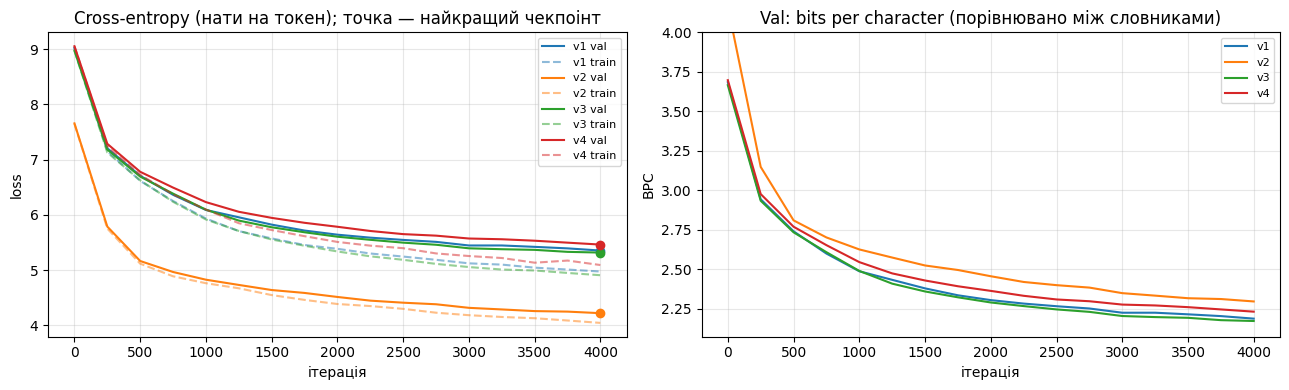

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for key, r in trained.items():
    h = r["history"]
    l, = axes[0].plot(h["iter"], h["val"], label=f"{key} val")
    axes[0].plot(h["iter"], h["train"], "--", color=l.get_color(), alpha=0.5, label=f"{key} train")
    axes[0].scatter([r["best_iter"]], [r["best_val_loss"]], color=l.get_color(), zorder=3)
    cpt = datasets_by_vocab[r["config"]["vocab_size"]]["chars_per_token"]
    axes[1].plot(h["iter"], np.array(h["val"]) / math.log(2) / cpt, label=key, color=l.get_color())
axes[0].set(title="Cross-entropy (нати на токен); точка — найкращий чекпоінт", xlabel="ітерація", ylabel="loss")
axes[1].set(title="Val: bits per character (порівнювано між словниками)", xlabel="ітерація", ylabel="BPC")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[1].set_ylim(top=4)
plt.tight_layout(); plt.show()

In [22]:
summary_rows = []
for key, r in trained.items():
    cfg = r["config"]
    cpt = datasets_by_vocab[cfg["vocab_size"]]["chars_per_token"]
    summary_rows.append({
        "варіант": key, "назва": cfg["name"], "параметрів, млн": round(r["n_params"] / 1e6, 2),
        "best val_loss": round(r["best_val_loss"], 3), "best iter": r["best_iter"],
        "фінальний val_loss": round(r["final_val_loss"], 3),
        "val BPC": round(r["best_val_loss"] / math.log(2) / cpt, 3),
        "розрив val−train (фінал)": round(r["history"]["val"][-1] - r["history"]["train"][-1], 3),
        "час, хв": round(r["train_time_s"] / 60, 1),
    })
minigpt_summary = pd.DataFrame(summary_rows).set_index("варіант")

update_results("3_minigpt", [
    {"experiment": "minigpt", "model": f"minigpt_{k}", "setting": row["назва"], "params_m": row["параметрів, млн"],
     "metric": metric, "value": row[col], "extra": f"best_iter={row['best iter']}"}
    for k, row in minigpt_summary.iterrows()
    for metric, col in [("best_val_loss", "best val_loss"), ("val_bpc", "val BPC")]
])
minigpt_summary

,назва,"параметрів, млн",best val_loss,best iter,фінальний val_loss,val BPC,розрив val−train (фінал),"час, хв"
варіант,,,,,,,,
v1,v1_base_vocab8k_ctx64_L4H4,2.86,5.356,3999,5.356,2.187,0.380,16.1
v2,v2_vocab2k,1.31,4.222,3999,4.222,2.296,0.176,10.7
v3,v3_deeper_L6H4,3.25,5.319,3999,5.319,2.172,0.410,21.6
v4,v4_ctx128_batch16,2.86,5.464,3999,5.464,2.231,0.370,19.1


### 3.3. Генерація на найкращих чекпоінтах (демо 3.10)

Промпт, температура, top-k і seed для всіх варіантів однакові. Кількість нових токенів підбираємо так, щоб кожен варіант згенерував ≈250 символів: токени v2 коротші, тож йому дається більше токенів.

In [23]:
PROMPT = "Україна — це"
TARGET_CHARS = 250

def generate_from_ckpt(key: str, prompt: str, temperature: float = 0.8, top_k: int = 40, seed: int = SEED) -> str:
    ckpt = torch.load(os.path.join(MODELS_DIR, f"minigpt_{key}.pt"), map_location=device, weights_only=False)
    cfg = ckpt["config"]
    model = build_model(cfg)
    model.load_state_dict(ckpt["state_dict"])
    tok = mg_tokenizers[cfg["vocab_size"]]
    max_new = int(TARGET_CHARS / datasets_by_vocab[cfg["vocab_size"]]["chars_per_token"])
    torch.manual_seed(seed)
    ids = torch.tensor([tok.encode(prompt).ids], dtype=torch.long, device=device)
    out = model.generate(ids, max_new, temperature=temperature, top_k=top_k)[0].tolist()
    del model, ckpt
    return tok.decode(out).replace("<eos>", " ⏎ ")

for key in VARIANTS:
    print(f"=== {key} ({VARIANTS[key]['name']}), val_loss={trained[key]['best_val_loss']:.3f} ===")
    print(generate_from_ckpt(key, PROMPT), "\n")

=== v1 (v1_base_vocab8k_ctx64_L4H4), val_loss=5.356 ===
Україна — це даєсь від себе на сцену, бо вона залишили. Він не можу.

Не з'являється про це й не могла, що у тому, що в чому?

Але я, і не було, як і не треба, а й не знаю, хто ми ніколи не було, що він не знаю, чому він би 

=== v2 (v2_vocab2k), val_loss=4.222 ===
Україна — це вкладаємо, а не лише для неї, щоби бачити. І «Вінка» підходом зібрала про що віддається в Україні. А він з ними, що наступати про її невизначеним.

Зговорювала під, що він не папляє: він.

Не, так багато років тому ніхто не було. Однак, в яких, в н 

=== v3 (v3_deeper_L6H4), val_loss=5.319 ===
Україна — це в ньому й не можеш. Побхідний механізм і не може бути «таблакитних» та й указів, що у разі не мають відповідати на відстані до уваги, хоча і не було, як і не треба.

Араближався на рік і, що він не було, ніж. Н 

=== v4 (v4_ctx128_batch16), val_loss=5.464 ===
Україна — це запитання — це не завжди. Високий, то той же не було не було. І ці!

Я хочу, що це н

In [24]:
# Ще один промпт з іншого жанру (художній), щоб перевірити, чи моделі підхоплюють регістр
for key in VARIANTS:
    print(f"=== {key} ===")
    print(generate_from_ckpt(key, "Вона відчинила двері й побачила", seed=7), "\n")

=== v1 ===
Вона відчинила двері й побачила. Але мені.

Терце, як почуваєш — сказав. Якщо не помітити?

Вимий, коли ми зможете?

Тут, що ти не лише не помітила. Просто, не буде. І це ще й не може бути, ніж вона хотіла ще, щоб і чому ж ми можемо в 

=== v2 ===
Вона відчинила двері й побачила: «Володу: вони не зможе, діти». Коси – божева, коли жила, коли діда?» — «Це. Під час не зможе. Ну-частіше, що?» – розмовірно, як, щоб і вперше, бо в одному, ніжні, не є, як і як стало не вистояли, що ствердж 

=== v3 ===
Вона відчинила двері й побачила!

У насичці про те, що до мене — з того, бо ти вже вроджав, що, коли я вже там мене, що я в себе. Певно, що ти в голові нехай, бо у нас, що, і я не можу, бо вти, щоб і на неї, бо в 

=== v4 ===
Вона відчинила двері й побачила. Але мені не можу: вони не було нічого не стільки, — сказав у нашому місті, то в неї, бо жила, аби не так само? — — Нь, що ти не можу не маєш. Просто там не буде. – Він ще не знає. І я, вона ти не, щоб і говорити, але я бачила 



### 3.3.1. Висновки щодо mini-GPT

| Варіант | best val_loss | val BPC | що змінено |
|---|---|---|---|
| v1 | 5,356 | 2,187 | база |
| v2 | **4,222** | 2,296 (гірше) | словник 8000 → 2000 |
| v3 | 5,319 | **2,172** (найкраще) | 4 → 6 шарів |
| v4 | 5,464 | 2,231 (гірше) | контекст 64 → 128, батч 32 → 16 |

**Який варіант кращий за `val_loss`.** Формально v2 (4,22 проти ≈5,3 в інших), але **це артефакт токенізації**. Loss рахується на *токен*, а токени словника 2000 коротші: 2,65 символу проти 3,53, тому кожен окремо передбачити легше. У перерахунку на символ (BPC) v2 найгірший. **Реально найкращий v3** (глибша мережа): 2,172 BPC.

**Чи помітно це в тексті.** Так, і саме за BPC, а не за val_loss. v2 найчастіше **вигадує неіснуючі слова** («кислотимами», «весрку», «бойзу», «встигнала»): з коротких шматків легко скласти «слово», якого немає. v1 і v3 майже завжди пишуть справжні слова й граматично прийнятні короткі фрагменти («як виявилося», «у цьому місті») і підхоплюють регістр промпту: після «Вона відчинила двері…» з'являються діалоги й розмовні звороти, як у художній прозі. Узгодженого змісту на довшому відрізку немає в жодного варіанта: для моделей на 1–3 млн параметрів після ≈4 епох це очікувано. Різниця v1 і v3 в тексті ледь помітна, як і різниця в BPC (0,7%).

**Що дало найбільший ефект.**
1. **Словник** (+5,0% BPC, тобто гірше). При зменшенні до 2000 модель, крім коротших токенів, ще й бачить за той самий `CONTEXT_LEN = 64` менше тексту (≈170 символів замість ≈225). Сам по собі менший словник лише перерозподіляє параметри: v2 має 1,3 млн проти 2,9 млн, більшість яких сидить в ембедингах і `lm_head`.
2. **Контекст 128 при батчі 16** (+2,0%, гірше). За однакової кількості токенів на крок довший контекст означає вдвічі менше *незалежних* прикладів у батчі, тобто шумніший градієнт. Позиційних ембедингів удвічі більше, і кожен навчається вдвічі рідше. Для недонавченої моделі, яка ще не вміє використовувати навіть 64 токени контексту, це програш. Можливо, переваги довгого контексту з'явилися б при значно довшому тренуванні.
3. **Глибина 6 шарів** (−0,7%, трохи краще) коштувала +14% параметрів і +34% часу. Ефект найменший серед трьох змін, але єдиний позитивний.

Головний висновок: при однаковому бюджеті тренування **для порівняння моделей з різними токенізаторами треба дивитися на BPC (або perplexity на символ / на слово), а не на `val_loss`**. Інакше висновок вийде протилежним до справжнього. Усі варіанти ще недонавчені (найкращий чекпоінт = останній), тож найбільше якості дало б просто довше тренування (див. питання 8).

### 3.4. Додатковий експеримент до питання 10: `EVAL_INTERVAL` 250 → 50

Повторюємо тренування найдешевшого варіанта (v2) на 1000 ітерацій двічі, з `EVAL_INTERVAL=250` і `EVAL_INTERVAL=50`, і окремо міряємо час, витрачений на `estimate_loss()`. Логи пишуться в `runs/eval_interval_*`.

Результати експерименту завантажено з /content/drive/MyDrive/lab3/runs/eval_interval_experiment/summary.json


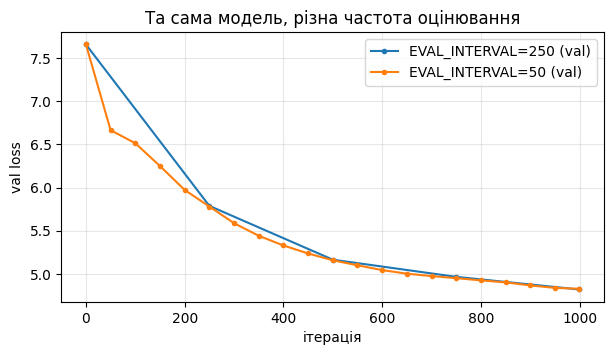

,EVAL_INTERVAL=250,EVAL_INTERVAL=50
оцінювань,5,21
"загальний час, с",166.4,197.1
"з них estimate_loss, с",10.4,43.9
частка часу на оцінку,6%,22%
best val_loss,4.822,4.829


In [25]:
EI_SUMMARY = os.path.join(RUNS_DIR, "eval_interval_experiment", "summary.json")
if os.path.exists(EI_SUMMARY) and not FORCE_RETRAIN:
    with open(EI_SUMMARY) as f:
        ei_results = json.load(f)
    print("Результати експерименту завантажено з", EI_SUMMARY)
else:
    ei_results = {}
    for interval in (250, 50):
        cfg = {**VARIANTS["v2"], "max_iters": 1000, "eval_interval": interval, "name": f"v2_eval{interval}"}
        print(f"EVAL_INTERVAL={interval}")
        ei_results[str(interval)] = train_variant(cfg, f"eval_interval_experiment/eval_{interval}", None, log_every_print=250)
    with open(EI_SUMMARY, "w") as f:
        json.dump(ei_results, f, indent=1)

fig, ax = plt.subplots(figsize=(7, 3.5))
for interval, r in ei_results.items():
    ax.plot(r["history"]["iter"], r["history"]["val"], marker="o", ms=3, label=f"EVAL_INTERVAL={interval} (val)")
ax.set(xlabel="ітерація", ylabel="val loss", title="Та сама модель, різна частота оцінювання"); ax.grid(alpha=0.3); ax.legend()
plt.show()

ei_table = pd.DataFrame({
    f"EVAL_INTERVAL={k}": {"оцінювань": len(r["history"]["iter"]),
                           "загальний час, с": round(r["train_time_s"], 1),
                           "з них estimate_loss, с": round(r["eval_time_s"], 1),
                           "частка часу на оцінку": f"{r['eval_time_s'] / r['train_time_s']:.0%}",
                           "best val_loss": round(r["best_val_loss"], 3)}
    for k, r in ei_results.items()})
ei_table

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

### Звільняємо пам'ять перед секціями 4–6

Усе потрібне із секцій 1–3 уже на диску: чекпоінти `models/minigpt_v*.pt`, токенізатори `models/tokenizer_bpe_*.json`, логи `runs/` і `results.csv`. Тому великі об'єкти можна видаляти.

In [26]:
for path in sorted(glob.glob(os.path.join(MODELS_DIR, "*"))) + [RESULTS_CSV]:
    print(f"{os.path.relpath(path, LAB_DIR):40s} {os.path.getsize(path) / 1e6:7.2f} MB")

for name in ["docs_df", "corpus_text", "words", "word_freq", "shuffled", "tok_train_texts", "tok_eval_texts",
             "eval_sample", "compare_tokenizers", "doc_texts", "ordered_docs", "datasets_by_vocab",
             "mg_tokenizers", "xb", "yb", "_tr", "_x1", "_y1", "bpe_word_freqs", "splits", "trained", "ei_results"]:
    globals().pop(name, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
try:
    import psutil
    print(f"RAM процесу: {psutil.Process().memory_info().rss / 1e9:.2f} GB")
except ImportError:
    pass

models/minigpt_v1.pt                       11.72 MB
models/minigpt_v2.pt                        5.55 MB
models/minigpt_v3.pt                       13.45 MB
models/minigpt_v4.pt                       12.54 MB
models/tokenizer_bpe_2000.json              0.16 MB
models/tokenizer_bpe_8000.json              0.75 MB
results.csv                                 0.00 MB
GPU: зайнято 0.01 GB
RAM процесу: 5.43 GB


### 4.0. Запустіть приклади виконання різних NLP задач

In [27]:
!pip install "transformers[sentencepiece]==5.18.0"

In [28]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [29]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [30]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

... (15 outputs left out)

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to create an easy-to-use library with JavaScript (to use JavaScript) and JavaScript as well as some other JavaScript frameworks. It is intended to teach you how you can use JavaScript in your project and to help you learn how to use JavaScript in your project.\n\n\nIntroduction\nYou can find all the basics of JavaScript in all of the following tutorial articles:\nJavaScript is a modern, powerful, and powerful language. It is an open source language. It is built on the principles of JavaScript and is used to help you to achieve a better understanding of the language and technology.\nLearning JavaScript\nThe fundamental principles of JavaScript are that it requires both Javascript and JavaScript to support the language. The two main components of JavaScript are how to write JavaScript, how to write JavaScript, and how to write JavaScript.\nJavaScript\nIn the end, JavaScript is a basic programming language and is used to create ap

In [31]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [32]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [33]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

Спільні налаштування для всіх pipeline-ів. Щоб не тримати кілька моделей у пам'яті одночасно, кожну задачу виконуємо в одній змінній `nlp` і після задачі звільняємо пам'ять через `release()`.

Моделі зі знанням української:

| Задача | Модель | Чому вона |
|---|---|---|
| sentiment-analysis | `tabularisai/multilingual-sentiment-analysis` | DistilBERT-multilingual, у списку мов є українська, 5 класів |
| zero-shot-classification | `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7` | NLI-модель, українська (`uk`) є в тренувальних даних |
| text-generation | `Qwen/Qwen2.5-1.5B-Instruct` | мала багатомовна instruct-модель, вміщається на T4 |
| fill-mask | `FacebookAI/xlm-roberta-base` | MLM на 100 мовах (CC-100), українська серед них |
| NER | `EvanD/xlm-roberta-base-ukrainian-ner-ukrner` | XLM-R, дотренований на українському NER-корпусі (lang-uk) |
| table-question-answering | `google/tapas-base-finetuned-wtq` | єдина поширена TAPAS-модель; навчена англійською, тому порівнюємо укр/англ питання |

In [34]:
from transformers import pipeline

PIPE_DEVICE = 0 if torch.cuda.is_available() else -1

def release():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

### 4.1.1. Sentiment analysis

In [35]:
nlp = pipeline("sentiment-analysis", model="tabularisai/multilingual-sentiment-analysis", device=PIPE_DEVICE)

uk_reviews = [
    "Ця кав'ярня — найкраще місце в місті, бариста просто чарівники!",
    "Замовлення йшло три тижні, а коробка приїхала розчавлена.",
    "Фільм нормальний, але другу половину можна було скоротити.",
    "Нарешті дочитав інструкцію до лабораторної — і все одразу запрацювало!",
    "Обіцяли швидкий інтернет, а ввечері маємо два мегабіти.",
]
for text, pred in zip(uk_reviews, nlp(uk_reviews)):
    print(f"{pred['label']:14s} {pred['score']:.2f}  {text}")
del nlp; release()

config.json:   0%|          | 0.00/851 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Very Positive  0.82  Ця кав'ярня — найкраще місце в місті, бариста просто чарівники!
Negative       0.46  Замовлення йшло три тижні, а коробка приїхала розчавлена.
Positive       0.44  Фільм нормальний, але другу половину можна було скоротити.
Positive       0.83  Нарешті дочитав інструкцію до лабораторної — і все одразу запрацювало!
Negative       0.66  Обіцяли швидкий інтернет, а ввечері маємо два мегабіти.


### 4.1.2. Zero-shot classification

Модель про класи нічого не знає: кожну мітку вона підставляє в гіпотезу (`hypothesis_template`) і перевіряє, чи випливає гіпотеза з тексту (NLI). Тому шаблон пишемо українською, як і текст.

In [36]:
nlp = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
               device=PIPE_DEVICE)

news = [
    "Національний банк знизив облікову ставку на пів відсоткового пункту.",
    "Збірна України з футболу вийшла до фінальної частини чемпіонату Європи.",
    "Науковці з Харкова створили новий матеріал для сонячних батарей.",
    "У Львові відкрили виставку сучасного українського живопису.",
    "Верховна Рада ухвалила закон про місцеві вибори.",
]
labels = ["економіка", "спорт", "наука", "культура", "політика"]
for text in news:
    r = nlp(text, candidate_labels=labels, hypothesis_template="Ця новина про {}.")
    top = ", ".join(f"{l} {s:.2f}" for l, s in zip(r["labels"][:3], r["scores"][:3]))
    print(f"{text}\n   → {top}")

# multi_label: кожна мітка оцінюється незалежно (сума ймовірностей ≠ 1)
r = nlp("Університет запустив стартап-інкубатор для студентів-програмістів за кошти ЄС.",
        candidate_labels=["освіта", "технології", "економіка", "спорт"], hypothesis_template="Ця новина про {}.",
        multi_label=True)
print("\nmulti_label:", {l: round(s, 2) for l, s in zip(r["labels"], r["scores"])})
del nlp; release()

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

Національний банк знизив облікову ставку на пів відсоткового пункту.
   → політика 0.62, економіка 0.20, наука 0.11
Збірна України з футболу вийшла до фінальної частини чемпіонату Європи.
   → спорт 0.98, політика 0.01, наука 0.00
Науковці з Харкова створили новий матеріал для сонячних батарей.
   → наука 0.99, економіка 0.00, політика 0.00
У Львові відкрили виставку сучасного українського живопису.
   → культура 0.99, наука 0.01, політика 0.00
Верховна Рада ухвалила закон про місцеві вибори.
   → політика 0.88, наука 0.06, культура 0.04

multi_label: {'освіта': 1.0, 'технології': 0.98, 'економіка': 0.09, 'спорт': 0.0}


### 4.1.3. Text generation

Instruct-модель отримує повідомлення в чат-форматі (`messages`), і pipeline сам застосовує шаблон чату. Для порівняння показано й «сире» продовження тексту без шаблону.

In [37]:
nlp = pipeline("text-generation", model="Qwen/Qwen2.5-1.5B-Instruct", dtype="auto", device=PIPE_DEVICE)

torch.manual_seed(SEED)
messages = [{"role": "user", "content": "Напиши коротку (3–4 речення) кумедну легенду про те, "
                                        "як у Житомирі з'явився перший трамвай."}]
out = nlp(messages, max_new_tokens=200, do_sample=True, temperature=0.7, top_p=0.9)
print(out[0]["generated_text"][-1]["content"])

print("\n--- продовження без чат-шаблону, 2 варіанти ---")
for o in nlp("Найкраща порада першокурснику технічного університету:", max_new_tokens=50,
             num_return_sequences=2, do_sample=True, temperature=0.9, return_full_text=False):
    print("•", o["generated_text"].strip())
del nlp; release()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'top_p', 'temperature', 'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=200) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Pass

В житті Змільції Вінницької в Житомирі вперше з'явився трамвай - це загадка для її досить багатої діяльністю. Немає ніяких спостережень, коли саме це сталося, але місце відомо: на початку 1908-го року. Трамваї стали одним із найбільш важливої елементів транспорту у цій області. Бажання за такою електричною системою буво створено, оскільки турбота не можна безпечно підтримати в житті ці

--- продовження без чат-шаблону, 2 варіанти ---
• відбувалася 10-го лекція - про компанії Apple

Translate this text to English.

English:

The best surprise for a first-year student of technical university: the tenth lecture –
• дуже кілька випробувань

1. Звичайне питання.

  1. В яких містах в Україні можна знайти таку сам


### 4.1.4. Fill-mask

У XLM-RoBERTa маска — це `<mask>`. У BERT-подібних моделях буває `[MASK]`, тому краще брати `nlp.tokenizer.mask_token`.

In [38]:
nlp = pipeline("fill-mask", model="FacebookAI/xlm-roberta-base", device=PIPE_DEVICE)
M = nlp.tokenizer.mask_token
for s in [f"Київ — столиця {M}.",
          f"Найпопулярніша українська страва — це {M}.",
          f"Студенти пишуть лабораторну роботу з машинного {M}.",
          f"Взимку в Карпатах можна кататися на {M}."]:
    preds = nlp(s, top_k=3)
    print(s, "→", [(p["token_str"].strip(), round(p["score"], 3)) for p in preds])
del nlp; release()

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Київ — столиця <mask>. → [('України', 0.441), ('.', 0.089), ('Україна', 0.053)]
Найпопулярніша українська страва — це <mask>. → [('риба', 0.154), ('хліб', 0.118), ('сир', 0.077)]
Студенти пишуть лабораторну роботу з машинного <mask>. → [('навчання', 0.881), ('управління', 0.013), ('контролю', 0.01)]
Взимку в Карпатах можна кататися на <mask>. → [('велосипед', 0.179), ('ски', 0.065), ('міні', 0.06)]


### 4.1.5. Named entity recognition

In [39]:
nlp = pipeline("ner", model="EvanD/xlm-roberta-base-ukrainian-ner-ukrner", aggregation_strategy="simple",
               device=PIPE_DEVICE)
ner_text = ("Тарас Шевченко народився в селі Моринці на Черкащині, а навчався в Петербурзькій академії мистецтв. "
            "Сьогодні Житомирська політехніка підписала угоду про співпрацю з компанією SoftServe.")
for ent in nlp(ner_text):
    print(f"{ent['entity_group']:5s} {ent['score']:.2f}  {ent['word']}")
del nlp; release()

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

... (3 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

PER   0.95  Тарас Шевченко
LOC   0.98  Моринці
LOC   0.99  Черкащині
ORG   0.98  Петербурзькій академії мистецтв
ORG   0.98  Житомирська політехніка
ORG   0.91  SoftServe


### 4.1.6. Table question answering

TAPAS для `wtq` навчений лише на англійських таблицях і питаннях, тому ставимо **ті самі питання українською та англійською** до української таблиці. Значення в таблиці мають бути рядками. Таблиця вигадана.

In [40]:
nlp = pipeline("table-question-answering", model="google/tapas-base-finetuned-wtq", device=PIPE_DEVICE)

table = pd.DataFrame({
    "Студент": ["Олена", "Андрій", "Марія", "Богдан", "Ірина"],
    "Група": ["ПІ-21", "ПІ-22", "ПІ-21", "КН-21", "КН-21"],
    "Бал за лабу": ["95", "78", "88", "64", "91"],
    "Здано вчасно": ["так", "ні", "так", "ні", "так"],
}).astype(str)
display(table)

qa_pairs = [
    ("Хто отримав найвищий бал?", "Who got the highest score?"),
    ("Який бал у Марії?", "What is Maria's score?"),   # TAPAS не знає, що Maria = Марія
    ("Скільки студентів у групі КН-21?", "How many students are in group КН-21?"),
    ("Яка сума балів групи ПІ-21?", "What is the total score of group ПІ-21?"),
    ("Який середній бал?", "What is the average score?"),
]
rows = []
for uk_q, en_q in qa_pairs:
    a_uk, a_en = nlp(table=table, query=uk_q), nlp(table=table, query=en_q)
    rows.append({"питання (uk)": uk_q, "відповідь (uk)": a_uk["answer"], "відповідь (en)": a_en["answer"]})
display(pd.DataFrame(rows))
del nlp; release()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

,Студент,Група,Бал за лабу,Здано вчасно
0,Олена,ПІ-21,95,так
1,Андрій,ПІ-22,78,ні
2,Марія,ПІ-21,88,так
3,Богдан,КН-21,64,ні
4,Ірина,КН-21,91,так


,питання (uk),відповідь (uk),відповідь (en)
0,Хто отримав найвищий бал?,Богдан,Олена
1,Який бал у Марії?,COUNT > Олена,AVERAGE > 88
2,Скільки студентів у групі КН-21?,Олена,"COUNT > Богдан, Ірина"
3,Яка сума балів групи ПІ-21?,"Олена, Марія","COUNT > 95, 88"
4,Який середній бал?,Олена,"AVERAGE > 95, 78, 88, 64, 91"


**Як читати результати секції 4.1 (на що звертати увагу у виводі):**
- **sentiment.** Порівняйте впевненість (`score`) на однозначних відгуках і на змішаному («нормальний, але…»). Для змішаних відгуків 5-класова шкала має проміжний клас `Neutral`.
- **zero-shot.** Модель не бачила жодного прикладу наших класів: для кожної мітки вона перевіряє, чи випливає гіпотеза «Ця новина про …» з тексту. Подивіться, чи правильна тема на першому місці і наскільки відірвана вона від другої. У `multi_label=True` мітки оцінюються незалежно, тож кілька можуть мати високу ймовірність одночасно.
- **text-generation.** Українська не основна мова Qwen2.5-1.5B, тому можливі граматичні помилки й кальки. Порівняйте чат-режим (модель виконує інструкцію) і «сире» продовження (модель просто дописує текст).
- **fill-mask.** Перевірте, чи узгоджені запропоновані слова за відмінком і родом із реченням. MLM бачить контекст з обох боків маски, тому це вміє краще за генеративну модель того ж розміру.
- **NER.** `aggregation_strategy="simple"` склеює субтокени в цілі сутності. Перевірте, чи правильно визначені межі багатослівних назв («Петербурзькій академії мистецтв», «Житомирська політехніка»).
- **table-QA.** TAPAS навчена лише англійською, тому порівняйте колонки «uk» та «en». Агреговані відповіді мають вигляд `SUM > …`, `AVERAGE > …`, `COUNT > …`. Будь-яка розбіжність між мовами наочно показує, що модель треба підбирати під мову.

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

### 5.1. Обрана задача: **sentiment-analysis**, метрики **Accuracy** і **F1** (позитивний клас)

Набір: 20 власних українських речень (10 позитивних, 10 негативних). Серед них є навмисно складні: заперечення з позитивним змістом («Не очікував, що… звучатимуть так добре»), позитивні відгуки зі словом «нічого», сарказм («Ну звісно, найкращий сервіс: третій день без води»).

Порівнюємо **три** багатомовні моделі з різними наборами міток:

| Модель | Архітектура | Мітки |
|---|---|---|
| `cardiffnlp/twitter-xlm-roberta-base-sentiment` | XLM-RoBERTa-base (≈278M) | negative / neutral / positive |
| `lxyuan/distilbert-base-multilingual-cased-sentiments-student` | DistilBERT-multilingual (≈135M) | positive / neutral / negative |
| `tabularisai/multilingual-sentiment-analysis` | DistilBERT-multilingual (≈135M) | Very Negative … Very Positive (5) |

Щоб мітки стали порівнянними, з повного розподілу (`top_k=None`) рахуємо P(pos) як суму ймовірностей усіх «positive»-міток і P(neg) як суму «negative»-міток. **Базове правило:** «позитив», якщо `P(pos) / (P(pos) + P(neg)) ≥ 0.5`, тобто нейтральна маса не заважає вибору між двома полюсами.

In [41]:
import evaluate

sent_data = [
    ("Обслуговування було блискавичним, а піца — просто неймовірна.", 1),
    ("Дякую за швидку доставку, все прийшло цілим і вчасно.", 1),
    ("Цей курс нарешті пояснив мені, як працюють трансформери.", 1),
    ("Готель затишний, персонал привітний, обов'язково повернемося.", 1),
    ("Не очікував, що недорогі навушники звучатимуть так добре.", 1),
    ("Лікарка уважно вислухала й усе детально пояснила.", 1),
    ("Концерт був фантастичним, я досі під враженням!", 1),
    ("Застосунок працює стабільно і не з'їдає батарею.", 1),
    ("Нічого зайвого, все зручно і зрозуміло — рекомендую.", 1),
    ("Книжка проковтнулася за один вечір, автор — молодець.", 1),
    ("Чекали на замовлення дві години, а суп принесли холодним.", 0),
    ("Після оновлення телефон постійно зависає.", 0),
    ("Продавець був грубим і відмовився повертати гроші.", 0),
    ("Ну звісно, найкращий сервіс: третій день без води.", 0),
    ("Фільм нудний, затягнутий і з передбачуваним фіналом.", 0),
    ("Не рекомендую цей магазин нікому.", 0),
    ("Кросівки розклеїлися вже за тиждень.", 0),
    ("Інструкція незрозуміла, а підтримка не відповідає.", 0),
    ("Квиток коштував шалені гроші, а звук був жахливий.", 0),
    ("Шкода витраченого часу.", 0),
]
sent_texts = [t for t, _ in sent_data]
sent_refs = [y for _, y in sent_data]

SENT_MODELS = {
    "xlmr-twitter": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    "distilbert-student": "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "tabularisai": "tabularisai/multilingual-sentiment-analysis",
}
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")


def pos_neg_neu(scores: list[dict]) -> tuple[float, float, float]:
    p_pos = sum(s["score"] for s in scores if "positive" in s["label"].lower())
    p_neg = sum(s["score"] for s in scores if "negative" in s["label"].lower())
    return p_pos, p_neg, max(0.0, 1.0 - p_pos - p_neg)


def predict(all_scores, rule: str = "pos_vs_neg", threshold: float = 0.5) -> list[int]:
    preds = []
    for scores in all_scores:
        p_pos, p_neg, p_neu = pos_neg_neu(scores)
        if rule == "pos_vs_neg":
            preds.append(int(p_pos / (p_pos + p_neg + 1e-9) >= threshold))
        elif rule == "argmax":   # пряма мітка моделі: нейтральне/негативне = «не позитив»
            top = max(scores, key=lambda s: s["score"])["label"].lower()
            preds.append(int("positive" in top))
    return preds


def score(preds) -> dict:
    return {"accuracy": accuracy_metric.compute(predictions=preds, references=sent_refs)["accuracy"],
            "f1": f1_metric.compute(predictions=preds, references=sent_refs, pos_label=1)["f1"]}

### 5.2. Порівняння моделей: метрика, швидкість, розмір

Швидкість міряємо після «прогріву» (перший виклик включає компіляцію та завантаження на GPU): 3 прогони по всіх 20 реченнях.

In [42]:
model_rows, raw_scores = [], {}
for short, model_id in SENT_MODELS.items():
    nlp = pipeline("text-classification", model=model_id, top_k=None, device=PIPE_DEVICE)
    nlp(sent_texts[:2])                                         # прогрів
    t0 = time.perf_counter()
    for _ in range(3):
        scores = nlp(sent_texts)
    ms_per_text = (time.perf_counter() - t0) / (3 * len(sent_texts)) * 1000
    raw_scores[short] = scores
    preds = predict(scores)
    m = score(preds)
    model_rows.append({"модель": short, "id": model_id,
                       "параметрів, млн": round(sum(p.numel() for p in nlp.model.parameters()) / 1e6, 1),
                       "accuracy": m["accuracy"], "f1": round(m["f1"], 3), "мс / речення": round(ms_per_text, 1),
                       "помилки": [i for i, (p, y) in enumerate(zip(preds, sent_refs)) if p != y]})
    del nlp; release()

model_comparison = pd.DataFrame(model_rows).set_index("модель")
model_comparison

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (7 outputs left out)

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,id,"параметрів, млн",accuracy,f1,мс / речення,помилки
модель,,,,,,
xlmr-twitter,cardiffnlp/twitter-xlm-roberta-base-sentiment,278.0,0.95,0.952,40.5,[13]
distilbert-student,lxyuan/distilbert-base-multilingual-cased-sentiments-student,135.3,0.70,0.625,6.1,"[0, 2, 3, 4, 5, 13]"
tabularisai,tabularisai/multilingual-sentiment-analysis,135.3,0.90,0.889,5.3,"[4, 9]"


In [43]:
# Детально: P(pos) кожної моделі на кожному реченні (✗ — помилка за базовим правилом)
detail = pd.DataFrame({"речення": sent_texts, "мітка": ["pos" if y else "neg" for y in sent_refs]})
for short, scores in raw_scores.items():
    pp = [pos_neg_neu(s) for s in scores]
    preds = predict(scores)
    detail[short] = [f"{p / (p + n + 1e-9):.2f}{'' if pr == y else ' ✗'}" for (p, n, _), pr, y in zip(pp, preds, sent_refs)]
detail

,речення,мітка,xlmr-twitter,distilbert-student,tabularisai
0,"Обслуговування було блискавичним, а піца — просто неймовірна.",pos,0.89,0.42 ✗,0.70
1,"Дякую за швидку доставку, все прийшло цілим і вчасно.",pos,0.98,0.74,0.97
2,"Цей курс нарешті пояснив мені, як працюють трансформери.",pos,0.88,0.38 ✗,0.86
3,"Готель затишний, персонал привітний, обов'язково повернемося.",pos,0.98,0.18 ✗,0.97
4,"Не очікував, що недорогі навушники звучатимуть так добре.",pos,0.84,0.42 ✗,0.12 ✗
5,Лікарка уважно вислухала й усе детально пояснила.,pos,0.83,0.38 ✗,0.98
6,"Концерт був фантастичним, я досі під враженням!",pos,0.98,0.83,0.96
7,Застосунок працює стабільно і не з'їдає батарею.,pos,0.53,0.69,0.76
8,"Нічого зайвого, все зручно і зрозуміло — рекомендую.",pos,0.97,0.66,0.94
9,"Книжка проковтнулася за один вечір, автор — молодець.",pos,0.98,0.59,0.09 ✗


### 5.3. Експерименти з налаштуваннями найкращої моделі

Беремо модель із найкращим F1 (за рівності — з кращою accuracy, далі — швидшу). Змінюємо **по одному** параметру відносно базового налаштування (`pos_vs_neg`, поріг 0.5, текст без змін):

1. **правило рішення** `argmax`: беремо пряму мітку моделі, тож «нейтрально» рахується як «не позитив»;
2. **поріг** 0.3 і 0.7 для `P(pos) / (P(pos) + P(neg))`;
3. **передобробка тексту**: нижній регістр і видалення пунктуації та емодзі;
4. **контекстний префікс** «Відгук клієнта: » перед кожним реченням (підказка домену).

In [44]:
best_short = model_comparison.sort_values(["f1", "accuracy", "мс / речення"], ascending=[False, False, True]).index[0]
best_model_id = SENT_MODELS[best_short]
print("Найкраща модель:", best_short, best_model_id)

def strip_text(t: str) -> str:
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s'’]", " ", t.lower())).strip()

nlp = pipeline("text-classification", model=best_model_id, top_k=None, device=PIPE_DEVICE)
base_scores = raw_scores[best_short]
experiments = [
    ("база: pos_vs_neg, поріг 0.5", predict(base_scores)),
    ("правило argmax", predict(base_scores, rule="argmax")),
    ("поріг 0.3", predict(base_scores, threshold=0.3)),
    ("поріг 0.7", predict(base_scores, threshold=0.7)),
    ("lowercase + без пунктуації", predict(nlp([strip_text(t) for t in sent_texts]))),
    ("префікс «Відгук клієнта: »", predict(nlp(["Відгук клієнта: " + t for t in sent_texts]))),
]
del nlp; release()

settings_rows = []
for short in SENT_MODELS:   # базове налаштування для всіх моделей
    m = score(predict(raw_scores[short]))
    settings_rows.append({"модель": short, "налаштування": "база: pos_vs_neg, поріг 0.5", **m})
for name, preds in experiments[1:]:
    settings_rows.append({"модель": best_short, "налаштування": name, **score(preds)})
settings_table = pd.DataFrame(settings_rows).round(3)

update_results("5_model_comparison", [
    {"experiment": "sentiment_uk_20", "model": SENT_MODELS[r["модель"]], "setting": r["налаштування"],
     "params_m": model_comparison.loc[r["модель"], "параметрів, млн"], "metric": metric, "value": r[metric],
     "extra": f"ms_per_text={model_comparison.loc[r['модель'], 'мс / речення']}"}
    for _, r in settings_table.iterrows() for metric in ("accuracy", "f1")
])
settings_table

Найкраща модель: xlmr-twitter cardiffnlp/twitter-xlm-roberta-base-sentiment


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,модель,налаштування,accuracy,f1
0,xlmr-twitter,"база: pos_vs_neg, поріг 0.5",0.95,0.952
1,distilbert-student,"база: pos_vs_neg, поріг 0.5",0.70,0.625
2,tabularisai,"база: pos_vs_neg, поріг 0.5",0.90,0.889
3,xlmr-twitter,правило argmax,0.85,0.842
4,xlmr-twitter,поріг 0.3,0.95,0.952
5,xlmr-twitter,поріг 0.7,0.90,0.900
6,xlmr-twitter,lowercase + без пунктуації,0.90,0.900
7,xlmr-twitter,префікс «Відгук клієнта: »,0.90,0.909


In [45]:
# Автоматичний підсумок за фактичними числами з таблиці вище
base = settings_table[settings_table["налаштування"].str.startswith("база")].set_index("модель")
best_cfg = settings_table.sort_values(["f1", "accuracy"], ascending=False).iloc[0]
model_spread = base["f1"].max() - base["f1"].min()
setting_f1 = settings_table[settings_table["модель"] == best_short]["f1"]
setting_spread = setting_f1.max() - setting_f1.min()
fastest = model_comparison["мс / речення"].idxmin()

print(f"Найкращий результат: {best_cfg['модель']} + «{best_cfg['налаштування']}» — "
      f"F1={best_cfg['f1']:.3f}, accuracy={best_cfg['accuracy']:.2f}.")
print(f"Розкид F1 між моделями (базове налаштування): {model_spread:.3f}; "
      f"розкид F1 між налаштуваннями найкращої моделі: {setting_spread:.3f}.")
print("Більше впливає", "ВИБІР МОДЕЛІ." if model_spread > setting_spread else
      ("НАЛАШТУВАННЯ." if setting_spread > model_spread else "однаково: вибір моделі й налаштування."))
print(f"Найшвидша модель: {fastest} ({model_comparison.loc[fastest, 'мс / речення']} мс/речення); "
      f"найкраща за F1: {best_short} ({model_comparison.loc[best_short, 'мс / речення']} мс/речення, "
      f"{model_comparison.loc[best_short, 'параметрів, млн']} млн параметрів).")

Найкращий результат: xlmr-twitter + «база: pos_vs_neg, поріг 0.5» — F1=0.952, accuracy=0.95.
Розкид F1 між моделями (базове налаштування): 0.327; розкид F1 між налаштуваннями найкращої моделі: 0.110.
Більше впливає ВИБІР МОДЕЛІ.
Найшвидша модель: tabularisai (5.3 мс/речення); найкраща за F1: xlmr-twitter (40.5 мс/речення, 278.0 млн параметрів).


### 5.4. Висновки

Конкретні числа та відповідь на питання «що впливає більше» друкує клітинка вище. Вона рахує їх із фактичних результатів, тож висновок не розійдеться з таблицею за повторного запуску. Загальні спостереження:

- **Чому вибір моделі зазвичай важить більше, ніж налаштування.** Моделі відрізняються даними, на яких їх дотренували (твіти 8 мовами, дистиляція з англійської моделі, синтетичні багатомовні дані), і саме від цього залежить, чи «розуміє» модель українські заперечення та сарказм. Налаштування лише зсувають межу рішення поверх тих самих ймовірностей. Якщо модель упевнено помиляється (наприклад, сарказм з P(pos) ≈ 0.9), жоден поріг цього не виправить. Чи так вийшло і на нашому наборі, показує порівняння двох «розкидів» F1 у клітинці вище.
- **Правило `argmax` проти `pos_vs_neg`** для 3- і 5-класових моделей вирішальне: на бінарному наборі «нейтрально» завжди помилка, якщо його не розподілити між полюсами. Саме тому базове правило порівнює лише P(pos) і P(neg).
- **Поріг** працює як компроміс precision/recall для позитивного класу: 0.3 «пропускає» більше позитивів (росте recall), 0.7 навпаки. На збалансованому наборі оптимум зазвичай біля 0.5, якщо модель добре відкалібрована.
- **Передобробка** (нижній регістр, без пунктуації) для `cased`-моделей частіше шкодить. Вони вчилися на «живому» тексті, де знак оклику чи регістр — теж сигнал тональності.
- **Швидкість і розмір.** DistilBERT-моделі (≈135M) приблизно вдвічі менші за XLM-R-base (≈278M; більша частина параметрів — ембединги словника на 250k токенів). Колонка «мс / речення» показує, чи це помітно на швидкості. Якщо якість близька, для продакшну вигідніша менша модель.
- **Обмеження.** На 20 прикладах одна помилка змінює accuracy на 5 п. п., тож різниці в 1–2 приклади статистично ненадійні. Для серйозного висновку потрібні сотні розмічених речень.

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

### 6.1. «Розбір відгуку по реченнях»: що хвалять і що виправити

**Проблема.** Відгуки в інтернет-магазині чи на картах майже завжди змішані: «Доставка швидка, але упаковка порвана, а ціна завищена». Одна загальна оцінка («нейтрально») власнику бізнесу нічого не каже.

**Що робить застосунок.** Розбиває відгук на речення і для кожного речення визначає:
1. **тональність**: найкраща модель із розділу 5, P(pos) − P(neg);
2. **аспект**, тобто про що йдеться: zero-shot mDeBERTa з розділу 4. Список аспектів користувач задає сам, наприклад для ресторану «кухня, офіціанти, інтер'єр».

Результат має три частини: текст із кольоровою підсвіткою речень, таблицю з числами та короткий підсумок **«що хвалять / що виправити»** за аспектами. Для українських відгуків нічого не потрібно дотреновувати: одна модель відповідає за тональність, інша за тему.

In [46]:
import gradio as gr

APP_SENT_MODEL = globals().get("best_model_id", "tabularisai/multilingual-sentiment-analysis")
APP_ZS_MODEL = "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"
app_sent = pipeline("text-classification", model=APP_SENT_MODEL, top_k=None, device=PIPE_DEVICE)
app_zs = pipeline("zero-shot-classification", model=APP_ZS_MODEL, device=PIPE_DEVICE)
print("Тональність:", APP_SENT_MODEL, "| Аспекти:", APP_ZS_MODEL)


def split_sentences(text: str) -> list[str]:
    parts = re.split(r"(?<=[.!?…])\s+|\n+|(?<=,)\s+(?=(?:але|проте|однак|зате)\s)", text.strip())
    return [p.strip() for p in parts if p and len(p.strip()) > 2]


def analyze_review(text: str, aspects_str: str, neutral_band: float = 0.2):
    sentences = split_sentences(text or "")
    aspects = [a.strip() for a in (aspects_str or "").split(",") if a.strip()]
    if not sentences or not aspects:
        return [], pd.DataFrame(), "Введіть текст відгуку та хоча б один аспект."

    highlighted, rows = [], []
    sent_scores = app_sent(sentences)
    for sentence, scores in zip(sentences, sent_scores):
        p_pos, p_neg, _ = pos_neg_neu(scores)
        polarity = p_pos - p_neg
        mood = "позитив" if polarity > neutral_band else "негатив" if polarity < -neutral_band else "нейтрально"
        zs = app_zs(sentence, candidate_labels=aspects, hypothesis_template="Це речення про {}.")
        aspect, conf = zs["labels"][0], zs["scores"][0]
        highlighted.append((sentence + " ", f"{mood} · {aspect}"))
        rows.append({"речення": sentence, "тональність": mood, "P(pos)−P(neg)": round(polarity, 2),
                     "аспект": aspect, "впевненість аспекту": round(conf, 2)})

    table = pd.DataFrame(rows)
    agg = table.groupby("аспект")["P(pos)−P(neg)"].mean().sort_values()
    praise = [f"**{a}** ({v:+.2f})" for a, v in agg[::-1].items() if v > neutral_band]
    fix = [f"**{a}** ({v:+.2f})" for a, v in agg.items() if v < -neutral_band]
    overall = table["P(pos)−P(neg)"].mean()
    summary = (f"### Загальний настрій: {overall:+.2f}\n"
               f"👍 **Хвалять:** {', '.join(praise) if praise else '—'}\n\n"
               f"🔧 **Варто виправити:** {', '.join(fix) if fix else '—'}\n\n"
               f"_Речень: {len(sentences)}. Шкала від −1 (дуже негативно) до +1 (дуже позитивно)._")
    return highlighted, table, summary

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Тональність: cardiffnlp/twitter-xlm-roberta-base-sentiment | Аспекти: MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7


In [47]:
# Перевіряємо функцію без інтерфейсу
_h, _t, _s = analyze_review(
    "Замовляв ноутбук у четвер, а привезли вже в п'ятницю зранку. Але коробка була пом'ята, "
    "а один кут зовсім розірваний. Сам ноутбук працює чудово, екран яскравий. Ціна, чесно, завищена.",
    "доставка, упаковка, якість товару, ціна, обслуговування")
display(_t)
print(_s)

,речення,тональність,P(pos)−P(neg),аспект,впевненість аспекту
0,"Замовляв ноутбук у четвер, а привезли вже в п'ятницю зранку.",нейтрально,-0.04,доставка,0.96
1,"Але коробка була пом'ята, а один кут зовсім розірваний.",негатив,-0.55,упаковка,0.91
2,"Сам ноутбук працює чудово, екран яскравий.",позитив,0.90,якість товару,0.76
3,"Ціна, чесно, завищена.",негатив,-0.91,ціна,0.94


### Загальний настрій: -0.15
👍 **Хвалять:** **якість товару** (+0.90)

🔧 **Варто виправити:** **ціна** (-0.91), **упаковка** (-0.55)

_Речень: 4. Шкала від −1 (дуже негативно) до +1 (дуже позитивно)._


In [48]:
EXAMPLES = [
    ["Замовляв ноутбук у четвер, а привезли вже в п'ятницю зранку. Але коробка була пом'ята, а один кут зовсім "
     "розірваний. Сам ноутбук працює чудово, екран яскравий. Ціна, чесно, завищена.",
     "доставка, упаковка, якість товару, ціна, обслуговування"],
    ["Борщ був неймовірний, як у бабусі! Офіціант забув про нас на пів години. Інтер'єр затишний, "
     "грає приємна музика. Рахунок принесли з помилкою.",
     "кухня, офіціанти, інтер'єр, рахунок"],
    ["Курс дуже практичний, лабораторні цікаві. Проте відеолекції записані з поганим звуком. "
     "Викладач швидко відповідає на питання в чаті.",
     "зміст курсу, якість відео, викладач"],
]
COLORS = {}
for ex_text, ex_aspects in EXAMPLES:
    for a in ex_aspects.split(","):
        for mood, c in (("позитив", "#2e7d32"), ("негатив", "#c62828"), ("нейтрально", "#9e9e9e")):
            COLORS[f"{mood} · {a.strip()}"] = c

with gr.Blocks(title="Розбір відгуку по реченнях") as demo:
    gr.Markdown("## 🧐 Розбір відгуку: що хвалять і що виправити\n"
                "Вставте відгук українською й перелічіть аспекти через кому. Кожне речення отримає "
                "тональність (зелений/червоний/сірий) і тему.")
    with gr.Row():
        with gr.Column(scale=3):
            inp_text = gr.Textbox(label="Відгук", lines=6, placeholder="Доставка швидка, але упаковка порвана…")
            inp_aspects = gr.Textbox(label="Аспекти (через кому)",
                                     value="доставка, упаковка, якість товару, ціна, обслуговування")
            inp_band = gr.Slider(0.0, 0.6, value=0.2, step=0.05, label="Зона «нейтрально» навколо 0")
            btn = gr.Button("Розібрати", variant="primary")
        with gr.Column(scale=4):
            out_summary = gr.Markdown()
            out_hl = gr.HighlightedText(label="Речення", color_map=COLORS, show_legend=False, combine_adjacent=False)
    out_table = gr.Dataframe(label="Деталі")
    gr.Examples(EXAMPLES, inputs=[inp_text, inp_aspects])
    btn.click(analyze_review, inputs=[inp_text, inp_aspects, inp_band], outputs=[out_hl, out_table, out_summary])

# У Colab інтерфейс з'явиться під клітинкою (share=True дає ще й публічне посилання на 72 год)
demo.launch(share=IN_COLAB)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a6ad889159db1537a0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**Чому це не «ще один чат-бот».** Застосунок поєднує дві **різні** готові моделі: класифікатор тональності, який виявився найкращим у розділі 5, і zero-shot NLI-класифікатор із розділу 4. Разом вони дають **аспектний аналіз тональності** (aspect-based sentiment analysis) без жодного дотреновування. Користувач сам задає список аспектів під свій бізнес (кав'ярня, курс, магазин) і за кілька секунд бачить, що саме треба виправити.

**Обмеження.** Розбиття на речення працює за пунктуацією та сполучниками «але/проте/однак/зате». Сарказм модель тональності розпізнає погано (див. розділ 5). Аспект обирається один на речення (`top-1`).

---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```